# Вектор ставок в один час

Момент t — один `hour_utc`. Состояние финансирования — вектор по монетам, отдельно для Bybit и для OKX. Корреляция считается между векторами этого часа, сводка — по ряду таких корреляций.

Старый общий Пирсон H1 складывал монета-часы как независимые наблюдения. Здесь этот расчёт не повторяется. Порог `|r| ≥ 0.2` из METHOD.md не сдвигается: медиана ряда либо выше этой метки, либо ниже.

Коллектор — `base_coin` строк `[0:337]` в `bybit_okx_universe.csv`. ICX и LRC без строк ставок, в вектор не входят. Сделки — уникальные `coin` в `tables/round_trips.csv`. Корреляция часа считается, если общих монет не меньше 5. Окно с 2026-07-20, строка при `both=1` и обеих `rate_per_8h`. `gap = bybit − okx`, проценты за 8 часов.


In [1]:
%matplotlib inline

import csv
import sys
from collections import defaultdict
from datetime import datetime
from pathlib import Path

import matplotlib.pyplot as plt

ROOT = Path("/Users/mishatrubik/Desktop/spread")
HERE = ROOT / "research" / "gear23_funding"
sys.path.insert(0, str(HERE))

from hypothesis_stats import median, pearson
from run_price_hypotheses import build_pairs

PANEL = HERE / "data" / "market_funding" / "by_coin.csv"
UNIVERSE = ROOT / "bybit_okx_universe.csv"
TRIPS = HERE / "tables" / "round_trips.csv"
WINDOW = "2026-07-20 00:00:00"
MIN_N = 5
SKIP = {"ICX", "LRC"}

plt.rcParams["font.family"] = "DejaVu Sans"
plt.rcParams["axes.unicode_minus"] = False
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.25
plt.rcParams["font.size"] = 9


def load_collector():
    coins = []
    with UNIVERSE.open(newline="") as handle:
        for row in csv.DictReader(handle):
            coins.append(row["base_coin"])
            if len(coins) >= 337:
                break
    return coins


def load_trades():
    coins, seen = [], set()
    with TRIPS.open(newline="") as handle:
        for row in csv.DictReader(handle):
            coin = row["coin"]
            if coin not in seen:
                seen.add(coin)
                coins.append(coin)
    return coins


def load_joint(coins):
    want = set(coins)
    panel = defaultdict(dict)
    with PANEL.open(newline="") as handle:
        for row in csv.DictReader(handle):
            coin = row["base_coin"]
            if coin not in want or row["hour_utc"] < WINDOW or row["both"] != "1":
                continue
            btxt, otxt = row["bybit_rate_per_8h_pct"], row["okx_rate_per_8h_pct"]
            if btxt == "" or otxt == "":
                continue
            bybit, okx = float(btxt), float(otxt)
            panel[row["hour_utc"]][coin] = (bybit, okx, bybit - okx)
    return dict(panel)


def hours_between(h0, h1):
    a = datetime.strptime(h0, "%Y-%m-%d %H:%M:%S")
    b = datetime.strptime(h1, "%Y-%m-%d %H:%M:%S")
    return (b - a).total_seconds() / 3600.0


def describe(label, requested, panel):
    present = {coin for rows in panel.values() for coin in rows}
    missing = [coin for coin in requested if coin not in present]
    hours = sorted(panel)
    counts = [len(panel[hour]) for hour in hours]
    print(
        f"{label}: запрошено {len(requested)}, в панели {len(present)}, "
        f"нет ряда: {', '.join(missing) if missing else '—'}"
    )
    print(
        f"  моментов {len(hours)} ({hours[0]} — {hours[-1]}), "
        f"монет в моменте медиана {median(counts):g}, "
        f"min {min(counts)}, max {max(counts)}, n<5: {sum(c < MIN_N for c in counts)}"
    )


def cross_section(panel, ix, iy):
    pairs, thin, flat = [], 0, 0
    for hour in sorted(panel):
        rows = list(panel[hour].values())
        if len(rows) < MIN_N:
            thin += 1
            continue
        value = pearson([row[ix] for row in rows], [row[iy] for row in rows])
        if value is None:
            flat += 1
            continue
        pairs.append((hour, value))
    return pairs, thin, flat


def persist(panel, ix):
    hours = sorted(panel)
    pairs, steps, no_next, flat = [], [], 0, 0
    for i, h0 in enumerate(hours):
        found = False
        for h1 in hours[i + 1:]:
            common = list(panel[h0].keys() & panel[h1].keys())
            if len(common) < MIN_N:
                continue
            found = True
            value = pearson(
                [panel[h0][coin][ix] for coin in common],
                [panel[h1][coin][ix] for coin in common],
            )
            if value is None:
                flat += 1
            else:
                pairs.append((h0, value))
                steps.append(hours_between(h0, h1))
            break
        if not found:
            no_next += 1
    return pairs, steps, no_next, flat


def gap_series(panel):
    series, thin = [], 0
    for hour in sorted(panel):
        gaps = [row[2] for row in panel[hour].values()]
        if len(gaps) < MIN_N:
            thin += 1
            continue
        series.append((hour, median(gaps), len(gaps)))
    return series, thin


def group_events(pairs):
    events = defaultdict(list)
    for pair in pairs:
        events[pair["hour"]].append((pair["coin"], pair["x"], pair["y"]))
    return events


def event_corr(events, coins):
    want = set(coins)
    pairs, thin, flat = [], 0, 0
    for hour in sorted(events):
        rows = [item for item in events[hour] if item[0] in want]
        if len(rows) < MIN_N:
            thin += 1
            continue
        value = pearson([item[1] for item in rows], [item[2] for item in rows])
        if value is None:
            flat += 1
            continue
        pairs.append((hour, value))
    return pairs, thin, flat


def report(label, pairs, extra=""):
    rs = [value for _, value in pairs]
    out = {"n": len(rs), "mean": None, "median": None, "share_pos": None, "lag1": None, "step_h": None}
    if not rs:
        print(f"{label}: нет моментов{extra}")
        return out
    out["mean"] = sum(rs) / len(rs)
    out["median"] = median(rs)
    out["share_pos"] = sum(value > 0.0 for value in rs) / len(rs)
    if len(rs) >= 3:
        out["lag1"] = pearson(rs[:-1], rs[1:])
    if len(pairs) >= 2:
        out["step_h"] = median([
            hours_between(pairs[i][0], pairs[i + 1][0]) for i in range(len(pairs) - 1)
        ])
    med = out["median"]
    side = "выше 0.2" if med > 0.2 else ("ниже 0.2" if med < 0.2 else "равно 0.2")
    module = "модуль ≥ 0.2" if abs(med) >= 0.2 else "модуль < 0.2"
    lag = "—" if out["lag1"] is None else f"{out['lag1']:.3f}"
    step = "—" if out["step_h"] is None else f"{out['step_h']:g}ч"
    print(
        f"{label}: n={out['n']}  mean={out['mean']:.3f}  median={med:.3f}  "
        f"доля r>0={out['share_pos']:.3f}  lag1={lag}  шаг ряда={step}  "
        f"медиана {side}, {module}{extra}"
    )
    return out


def report_gap(label, series, thin):
    meds = [item[1] for item in series]
    out = {
        "n": len(meds),
        "mean": sum(meds) / len(meds),
        "median": median(meds),
        "share_neg": sum(value < 0.0 for value in meds) / len(meds),
        "share_zero": sum(value == 0.0 for value in meds) / len(meds),
    }
    print(
        f"{label}: n={out['n']}  mean={out['mean']:.4f}  median={out['median']:.4f}  "
        f"доля часов с медианой < 0: {out['share_neg']:.3f}  "
        f"доля часов с медианой = 0: {out['share_zero']:.3f}  пропущено n<5: {thin}"
    )
    return out


def plot_weekly(series_c, series_t):
    def pack(series):
        buckets = defaultdict(list)
        for hour, med, _n in series:
            year, week, _day = datetime.strptime(hour, "%Y-%m-%d %H:%M:%S").isocalendar()
            buckets[(year, week)].append(med)
        return {key: median(values) for key, values in buckets.items()}

    left, right = pack(series_c), pack(series_t)
    keys = sorted(set(left) | set(right))
    labels = [f"{year}-W{week:02d}" for year, week in keys]
    fig, ax = plt.subplots(figsize=(7.2, 2.5))
    ax.plot(labels, [left.get(key, float("nan")) for key in keys], color="#1f4e79", lw=1.8, marker="o", ms=3.5, label="коллектор")
    ax.plot(labels, [right.get(key, float("nan")) for key in keys], color="#d17a22", lw=1.3, ls="--", marker="o", ms=3, label="11 сделок")
    ax.axhline(0.0, color="#888888", lw=0.6)
    ax.set_ylabel("медиана gap, % за 8ч")
    ax.set_title("Недельная медиана кросс-секционного gap")
    ax.legend(frameon=False, fontsize=8)
    ax.tick_params(axis="x", labelrotation=45, labelsize=8)
    fig.tight_layout()
    plt.show()


collector = load_collector()
trades = load_trades()
POOLS = {
    "коллектор": [coin for coin in collector if coin not in SKIP],
    "сделки": trades,
}
panel_c = load_joint(POOLS["коллектор"])
panel_t = load_joint(POOLS["сделки"])
OUT = {}
describe("коллектор", collector, panel_c)
describe("сделки", trades, panel_t)
print("монеты сделок:", ", ".join(trades))


коллектор: запрошено 337, в панели 335, нет ряда: ICX, LRC
  моментов 620 (2026-07-20 16:00:00 — 2026-10-22 13:00:00), монет в моменте медиана 157, min 1, max 335, n<5: 56
сделки: запрошено 11, в панели 11, нет ряда: —
  моментов 592 (2026-07-20 16:00:00 — 2026-10-22 13:00:00), монет в моменте медиана 8, min 1, max 11, n<5: 28
монеты сделок: API3, TRUST, WAL, LA, RSR, BLUR, SAND, CT, MEW, IOST, DOOD


## Содвижение Bybit и OKX

В час t — корреляция Пирсона вектора `rate_per_8h` Bybit с таким же вектором OKX по монетам этого часа. Так видно, движутся ли две биржи вместе в одном срезе. Лаг 1 — автокорреляция этого ряда r по соседним оставленным часам. Совместный шаг панели чаще 4 часа.


In [2]:
for key, panel in (("коллектор", panel_c), ("сделки", panel_t)):
    pairs, thin, flat = cross_section(panel, 0, 1)
    OUT[f"{key}_bb_okx"] = report(
        f"{key} Bybit–OKX",
        pairs,
        f"  (n<5: {thin}, дисперсия 0: {flat})",
    )


коллектор Bybit–OKX: n=564  mean=0.814  median=0.878  доля r>0=1.000  lag1=0.431  шаг ряда=4ч  медиана выше 0.2, модуль ≥ 0.2  (n<5: 56, дисперсия 0: 0)
сделки Bybit–OKX: n=490  mean=0.757  median=0.981  доля r>0=0.908  lag1=0.385  шаг ряда=4ч  медиана выше 0.2, модуль ≥ 0.2  (n<5: 28, дисперсия 0: 74)


## Устойчивость вектора

Для каждого t берётся ближайший следующий совместный час, где пересечение монет не меньше 5, и считается corr(вектор_t, вектор следующего часа). Отдельно ставки Bybit, ставки OKX и gap. Это память среза по монетам, не автокорреляция gap внутри одной монеты.


In [3]:
for key, panel in (("коллектор", panel_c), ("сделки", panel_t)):
    for name, ix in (("Bybit", 0), ("OKX", 1), ("gap", 2)):
        pairs, steps, no_next, flat = persist(panel, ix)
        step = "—" if not steps else f"{median(steps):g}ч"
        OUT[f"{key}_pers_{name}"] = report(
            f"{key} устойчивость {name}",
            pairs,
            f"  (нет следующего вектора {no_next}, дисперсия 0: {flat}, шаг до него {step})",
        )


коллектор устойчивость Bybit: n=563  mean=0.699  median=0.762  доля r>0=0.998  lag1=0.353  шаг ряда=4ч  медиана выше 0.2, модуль ≥ 0.2  (нет следующего вектора 57, дисперсия 0: 0, шаг до него 4ч)
коллектор устойчивость OKX: n=563  mean=0.813  median=0.867  доля r>0=1.000  lag1=0.340  шаг ряда=4ч  медиана выше 0.2, модуль ≥ 0.2  (нет следующего вектора 57, дисперсия 0: 0, шаг до него 4ч)
коллектор устойчивость gap: n=563  mean=0.376  median=0.427  доля r>0=0.877  lag1=0.036  шаг ряда=4ч  медиана выше 0.2, модуль ≥ 0.2  (нет следующего вектора 57, дисперсия 0: 0, шаг до него 4ч)
сделки устойчивость Bybit: n=421  mean=0.762  median=0.991  доля r>0=0.898  lag1=0.250  шаг ряда=4ч  медиана выше 0.2, модуль ≥ 0.2  (нет следующего вектора 29, дисперсия 0: 142, шаг до него 4ч)
сделки устойчивость OKX: n=422  mean=0.874  median=0.997  доля r>0=0.964  lag1=0.328  шаг ряда=4ч  медиана выше 0.2, модуль ≥ 0.2  (нет следующего вектора 29, дисперсия 0: 141, шаг до него 4ч)
сделки устойчивость gap: n=4

## Медиана gap по часу

В час t берётся медиана gap по монетам; час с меньше чем 5 монетами пропускается. Плюс gap значит, что длинный спред — шорт Bybit, лонг OKX — в этот час получает финансирование. Минус значит, что хедж платит. Ниже — среднее, медиана и доля часов с отрицательной медианой. Линия — недельная медиана того же ряда.


коллектор: n=564  mean=0.0000  median=0.0000  доля часов с медианой < 0: 0.000  доля часов с медианой = 0: 1.000  пропущено n<5: 56
сделки: n=564  mean=0.0003  median=0.0000  доля часов с медианой < 0: 0.021  доля часов с медианой = 0: 0.897  пропущено n<5: 28


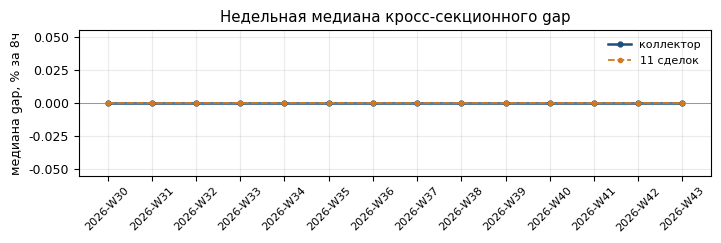

In [4]:
gap_c, thin_c = gap_series(panel_c)
gap_t, thin_t = gap_series(panel_t)
OUT["коллектор_gap"] = report_gap("коллектор", gap_c, thin_c)
OUT["сделки_gap"] = report_gap("сделки", gap_t, thin_t)
plot_weekly(gap_c, gap_t)


## Вектор ставки и вектор цены

Биржа стыкуется только со своей ценой. Цена в метку начисления — close часовой свечи, которая в эту метку заканчивается. Доходность приведена к 8 часам множителем `8 / длина интервала`, как в `run_price_hypotheses.py`. В один час входят монеты с начислением в этот час; длина интервала у монет может различаться. Час, где у биржи меньше 5 таких монет, пропускается.

H5 — вектор `(ставка_t − ставка_пред)` против вектора доходности за тот же уже закрытый интервал. H6 — вектор напечатанной `ставка_t` против вектора доходности до следующего начисления этой биржи. В час решения видна напечатанная ставка и ещё не видна следующая доходность: это H6.


In [5]:
union = list(dict.fromkeys(POOLS["коллектор"] + POOLS["сделки"]))
for exchange in ("bybit", "okx"):
    built = build_pairs(exchange, union)
    cov = built["coverage"]
    miss = sorted(set(cov["missing_funding"]) | set(cov["missing_price"]))
    tail = f", без ряда: {', '.join(miss)}" if miss else ""
    print(
        f"{exchange}: монет со ставкой и ценой {cov['coins_with_both']} из {cov['coins_requested']}, "
        f"пар H5 {len(built['H5'])}, пар H6 {len(built['H6'])}{tail}"
    )
    grouped = {kind: group_events(built[kind]) for kind in ("H5", "H6")}
    for kind in ("H5", "H6"):
        for key, coins in POOLS.items():
            pairs, thin, flat = event_corr(grouped[kind], coins)
            OUT[f"{key}_{exchange}_{kind}"] = report(
                f"{key} {exchange} {kind}",
                pairs,
                f"  (n<5: {thin}, дисперсия 0: {flat})",
            )


bybit: монет со ставкой и ценой 336 из 336, пар H5 141688, пар H6 141688
коллектор bybit H5: n=567  mean=-0.061  median=-0.042  доля r>0=0.377  lag1=0.072  шаг ряда=4ч  медиана ниже 0.2, модуль < 0.2  (n<5: 556, дисперсия 0: 0)
сделки bybit H5: n=544  mean=-0.161  median=-0.173  доля r>0=0.384  lag1=0.098  шаг ряда=4ч  медиана ниже 0.2, модуль < 0.2  (n<5: 556, дисперсия 0: 23)
коллектор bybit H6: n=567  mean=0.033  median=0.027  доля r>0=0.596  lag1=-0.020  шаг ряда=4ч  медиана ниже 0.2, модуль < 0.2  (n<5: 556, дисперсия 0: 0)
сделки bybit H6: n=522  mean=0.079  median=0.095  доля r>0=0.577  lag1=-0.114  шаг ряда=4ч  медиана ниже 0.2, модуль < 0.2  (n<5: 556, дисперсия 0: 45)


okx: монет со ставкой и ценой 336 из 336, пар H5 143338, пар H6 143338
коллектор okx H5: n=563  mean=-0.083  median=-0.056  доля r>0=0.346  lag1=0.107  шаг ряда=4ч  медиана ниже 0.2, модуль < 0.2  (n<5: 248, дисперсия 0: 0)
сделки okx H5: n=541  mean=-0.096  median=-0.100  доля r>0=0.440  lag1=0.047  шаг ряда=4ч  медиана ниже 0.2, модуль < 0.2  (n<5: 248, дисперсия 0: 22)
коллектор okx H6: n=563  mean=0.017  median=0.011  доля r>0=0.533  lag1=-0.040  шаг ряда=4ч  медиана ниже 0.2, модуль < 0.2  (n<5: 248, дисперсия 0: 0)
сделки okx H6: n=533  mean=0.044  median=0.040  доля r>0=0.544  lag1=-0.081  шаг ряда=4ч  медиана ниже 0.2, модуль < 0.2  (n<5: 248, дисперсия 0: 30)


## Что совпадает на двух пулах

Ниже медианы тех же рядов на векторе коллектора и на векторе 11 монет. Порог живого входа отсюда не ставится. H4 и H7 (`spread_long`) отсутствуют: локальные тики — тестовый день, не архив за окно ставок.


In [6]:
items = [
    ("Bybit–OKX", "коллектор_bb_okx", "сделки_bb_okx"),
    ("устойчивость Bybit", "коллектор_pers_Bybit", "сделки_pers_Bybit"),
    ("устойчивость OKX", "коллектор_pers_OKX", "сделки_pers_OKX"),
    ("устойчивость gap", "коллектор_pers_gap", "сделки_pers_gap"),
    ("H5 Bybit", "коллектор_bybit_H5", "сделки_bybit_H5"),
    ("H6 Bybit", "коллектор_bybit_H6", "сделки_bybit_H6"),
    ("H5 OKX", "коллектор_okx_H5", "сделки_okx_H5"),
    ("H6 OKX", "коллектор_okx_H6", "сделки_okx_H6"),
]
for title, left_key, right_key in items:
    left, right = OUT[left_key]["median"], OUT[right_key]["median"]
    print(f"{title}: коллектор {left:.3f}, сделки {right:.3f}")

def grab(keys):
    return [OUT[key]["median"] for key in keys]

move_keys = [
    "коллектор_bb_okx", "сделки_bb_okx",
    "коллектор_pers_Bybit", "сделки_pers_Bybit",
    "коллектор_pers_OKX", "сделки_pers_OKX",
    "коллектор_pers_gap", "сделки_pers_gap",
]
h5_keys = ["коллектор_bybit_H5", "сделки_bybit_H5", "коллектор_okx_H5", "сделки_okx_H5"]
h6_keys = ["коллектор_bybit_H6", "сделки_bybit_H6", "коллектор_okx_H6", "сделки_okx_H6"]
move, h5, h6 = grab(move_keys), grab(h5_keys), grab(h6_keys)
if all(value > 0.2 for value in move) and OUT["коллектор_bb_okx"]["lag1"] > 0 and OUT["сделки_bb_okx"]["lag1"] > 0:
    print("Содвижение Bybit–OKX и устойчивость Bybit, OKX и gap: медиана выше 0.2 на обоих пулах, лаг 1 содвижения положительный.")
if all(value < 0 for value in h5) and all(value < 0.2 for value in h5):
    print("H5, обе биржи и оба пула: медиана отрицательная и ниже 0.2.")
if all(value > 0 for value in h6) and all(value < 0.2 for value in h6):
    print("H6, обе биржи и оба пула: медиана положительная и ниже 0.2.")
if OUT["коллектор_gap"]["median"] == 0 and OUT["сделки_gap"]["median"] == 0:
    print(
        f"Медиана ряда медиан gap равна 0 на обоих пулах. "
        f"На коллекторе она равна 0 в доле часов {OUT['коллектор_gap']['share_zero']:.3f}."
    )
print("Порог живого входа из этих чисел не выводится.")
print("H4 и H7 отсутствуют: локальные тики — тестовый день, spread_long за окно ставок не собран.")


Bybit–OKX: коллектор 0.878, сделки 0.981
устойчивость Bybit: коллектор 0.762, сделки 0.991
устойчивость OKX: коллектор 0.867, сделки 0.997
устойчивость gap: коллектор 0.427, сделки 0.713
H5 Bybit: коллектор -0.042, сделки -0.173
H6 Bybit: коллектор 0.027, сделки 0.095
H5 OKX: коллектор -0.056, сделки -0.100
H6 OKX: коллектор 0.011, сделки 0.040
Содвижение Bybit–OKX и устойчивость Bybit, OKX и gap: медиана выше 0.2 на обоих пулах, лаг 1 содвижения положительный.
H5, обе биржи и оба пула: медиана отрицательная и ниже 0.2.
H6, обе биржи и оба пула: медиана положительная и ниже 0.2.
Медиана ряда медиан gap равна 0 на обоих пулах. На коллекторе она равна 0 в доле часов 1.000.
Порог живого входа из этих чисел не выводится.
H4 и H7 отсутствуют: локальные тики — тестовый день, spread_long за окно ставок не собран.


## Период начисления

`interval_hours` — часы от предыдущего начисления той же серии. Первая точка серии пустая и в счёт не входит. Зазор относится к 1, 4 или 8 часам, только если он не дальше 0.25 ч от этой метки. Иной зазор — «другое». Медиана монеты — медиана её зазоров, корзина та же.

Ниже окно с 2026-07-20 и пул коллектора: `base_coin` строк `[0:337]` в `bybit_okx_universe.csv`. Текущий интервал Bybit — `current_bybit_interval_hours`. Разные корзины у этого интервала и у медианы зазоров в окне — расхождение.

На всём файле доли OKX те же: публичная история начинается в этом окне. У Bybit на полной истории зазор 1 ч составляет 1.72% начислений коллектора, в окне — 0.58%. Медиана CL на полной истории равна 4 ч при текущих 8 ч; в этом окне медиана CL уже 8 ч.


In [7]:
import csv
import sys
from collections import Counter, defaultdict
from pathlib import Path

ROOT = Path("/Users/mishatrubik/Desktop/spread")
HERE = ROOT / "research" / "gear23_funding"
sys.path.insert(0, str(HERE))
from hypothesis_stats import median

WINDOW = "2026-07-20 00:00:00"
SETTLEMENTS = HERE / "data" / "market_funding" / "settlements.csv"
COVERAGE = HERE / "data" / "market_funding" / "coverage.csv"
UNIVERSE = ROOT / "bybit_okx_universe.csv"
CANON = (1.0, 4.0, 8.0)
ORDER = ("1", "4", "8", "other")
TITLE = {"bybit": "Bybit", "okx": "OKX"}


def pct(count, total):
    value = 100.0 * count / total
    if count and value < 0.005:
        return f"{value:.3f}%"
    return f"{value:.2f}%"


def gap_bucket(value):
    best = min(CANON, key=lambda item: abs(value - item))
    if abs(value - best) <= 0.25:
        return str(int(best))
    return "other"


def load_collector():
    coins = []
    with UNIVERSE.open(newline="") as handle:
        for row in csv.DictReader(handle):
            coins.append(row["base_coin"])
            if len(coins) >= 337:
                break
    return coins


requested = load_collector()
pool = set(requested)
gaps = {"bybit": defaultdict(list), "okx": defaultdict(list)}
with SETTLEMENTS.open(newline="") as handle:
    for row in csv.DictReader(handle):
        if row["base_coin"] not in pool or row["hour_utc"] < WINDOW or row["interval_hours"] == "":
            continue
        gaps[row["exchange"]][row["base_coin"]].append(float(row["interval_hours"]))

current = {}
with COVERAGE.open(newline="") as handle:
    for row in csv.DictReader(handle):
        if row["exchange"] == "bybit" and row["base_coin"] in pool and row["current_bybit_interval_hours"] != "":
            current[row["base_coin"]] = float(row["current_bybit_interval_hours"])

print(f"окно >= {WINDOW}, коллектор {len(requested)}")
for exchange in ("bybit", "okx"):
    series = gaps[exchange]
    missing = [coin for coin in requested if coin not in series]
    counts, other, med_counts = Counter(), Counter(), Counter()
    for coin, values in series.items():
        med_counts[gap_bucket(median(values))] += 1
        for hours in values:
            label = gap_bucket(hours)
            counts[label] += 1
            if label == "other":
                other[round(hours, 1)] += 1
    total = sum(counts.values())
    print(
        f"{TITLE[exchange]}: зазоров {total}, серий {len(series)}, "
        f"нет ряда: {', '.join(missing) if missing else '—'}"
    )
    for label in ORDER:
        caption = "другое" if label == "other" else f"{label} ч"
        print(f"  зазор {caption}: {counts[label]} ({pct(counts[label], total)})")
    if other:
        text = ", ".join(f"{value:.1f} × {count}" for value, count in other.most_common())
        print(f"  другое, шаг 0.1 ч: {text}")
    print(f"  медиана серии, монет {len(series)}")
    for label in ORDER:
        caption = "другое" if label == "other" else f"{label} ч"
        print(f"    {caption}: {med_counts[label]} ({pct(med_counts[label], len(series))})")

disagree = []
for coin, values in sorted(gaps["bybit"].items()):
    now = current.get(coin)
    if now is None:
        continue
    center = median(values)
    if gap_bucket(center) != gap_bucket(now):
        disagree.append((coin, center, now))
print(f"Bybit, текущий интервал и медиана зазора в разных корзинах: {len(disagree)} из {len(gaps['bybit'])}")
for coin, center, now in disagree:
    print(f"  {coin}: медиана {center:g} ч, сейчас {now:g} ч")


окно >= 2026-07-20 00:00:00, коллектор 337
Bybit: зазоров 141897, серий 335, нет ряда: ICX, LRC
  зазор 1 ч: 828 (0.58%)
  зазор 4 ч: 92058 (64.88%)
  зазор 8 ч: 49005 (34.54%)
  зазор другое: 6 (0.004%)
  другое, шаг 0.1 ч: 2.0 × 3, 3.0 × 2, 6.0 × 1
  медиана серии, монет 335
    1 ч: 0 (0.00%)
    4 ч: 162 (48.36%)
    8 ч: 173 (51.64%)
    другое: 0 (0.00%)
OKX: зазоров 143535, серий 335, нет ряда: ICX, LRC
  зазор 1 ч: 159 (0.11%)
  зазор 4 ч: 97759 (68.11%)
  зазор 8 ч: 45340 (31.59%)
  зазор другое: 277 (0.19%)
  другое, шаг 0.1 ч: 2.0 × 277
  медиана серии, монет 335
    1 ч: 0 (0.00%)
    4 ч: 175 (52.24%)
    8 ч: 160 (47.76%)
    другое: 0 (0.00%)
Bybit, текущий интервал и медиана зазора в разных корзинах: 1 из 335
  IOST: медиана 8 ч, сейчас 1 ч


## Период и волатильность

Окно `hour_utc` с 2026-07-20 включительно до 2026-10-23 не включая. Пул — 335 монет коллектора, строки `[0:337]` в `bybit_okx_universe.csv`, у которых есть ряд ставок. ICX и LRC в панели нет. Период монеты — медиана её `interval_hours` в этом окне; первая пустая точка не входит. Корзины — 4 ч и 8 ч. Медианы 1 ч нет.

Волатильность монеты — стандартное отклонение её часовых лог-доходностей на этой бирже, делитель n−1. Цена часа — close свечи, которая заканчивается в этот час. В доходность входят только соседние часы. Минимум 100 доходностей; здесь у каждой монеты их 2273.

Ликвидность не измерена. В кэше цен у строки только `ts_ms` и `close`, оборота нет. Рынок заново не скачивался.

Bybit: 4 ч — 162 монеты, медиана vol 1.067594e-02; 8 ч — 173 монеты, медиана vol 8.394405e-03; отношение 4/8 = 1.2718. Спирмен интервала и vol -0.4481, Пирсон -0.4016. Строго выше общей медианы vol — 114 из 162. Короткий период совпадает с более высокой волатильностью.

OKX: 4 ч — 175 монет, медиана vol 1.064776e-02; 8 ч — 160 монет, медиана vol 8.233274e-03; отношение 4/8 = 1.2933. Спирмен -0.4733, Пирсон -0.4359. Строго выше общей медианы vol — 123 из 175. Короткий период совпадает с более высокой волатильностью.

Корзину 1/4/8 ч внутри окна меняют 9 монет Bybit и 11 монет OKX. Список — в выводе ячейки. Сравнение волатильности до и после смены не строилось: монета остаётся в корзине своей медианы. У Bybit CL зазор 4 ч держится с 20 июля по 7 августа, затем 8 ч. У Bybit IOST зазор 1 ч есть 10–15 сентября и снова с 22 октября до конца ряда.

Порог живого входа из этих чисел не выводится.


In [8]:
import csv
import json
import math
import sys
from collections import defaultdict
from datetime import datetime, timezone
from pathlib import Path

ROOT = Path("/Users/mishatrubik/Desktop/spread")
HERE = ROOT / "research" / "gear23_funding"
sys.path.insert(0, str(HERE))
from hypothesis_stats import median, pearson, spearman

WINDOW_START = "2026-07-20 00:00:00"
WINDOW_END = "2026-10-23 00:00:00"
START = datetime(2026, 7, 20, tzinfo=timezone.utc)
END = datetime(2026, 10, 23, tzinfo=timezone.utc)
START_MS = int(START.timestamp() * 1000)
END_MS = int(END.timestamp() * 1000)
HOUR_MS = 3_600_000
CANDLE_START_MS = START_MS - HOUR_MS
CANON = (1.0, 4.0, 8.0)
MIN_RETURNS = 100
PRICE_ROOT = HERE / "data" / "market_funding" / "prices"
SETTLEMENTS = HERE / "data" / "market_funding" / "settlements.csv"
UNIVERSE = ROOT / "bybit_okx_universe.csv"
TITLE = {"bybit": "Bybit", "okx": "OKX"}


def gap_bucket(value):
    best = min(CANON, key=lambda item: abs(value - item))
    if abs(value - best) <= 0.25:
        return int(best)
    return None


def stdev(values):
    n = len(values)
    center = sum(values) / n
    return math.sqrt(sum((value - center) ** 2 for value in values) / (n - 1))


def load_collector():
    coins = []
    with UNIVERSE.open(newline="") as handle:
        for row in csv.DictReader(handle):
            coins.append(row["base_coin"])
            if len(coins) >= 337:
                break
    return coins


def hourly_log_returns(prices):
    returns = []
    previous_price = None
    previous_ts = None
    ts = START_MS
    while ts < END_MS:
        price = prices.get(ts - HOUR_MS)
        if (
            price is not None
            and price > 0.0
            and previous_price is not None
            and ts - previous_ts == HOUR_MS
        ):
            returns.append(math.log(price / previous_price))
        if price is not None and price > 0.0:
            previous_price = price
            previous_ts = ts
        elif price is not None:
            previous_price = None
            previous_ts = None
        ts += HOUR_MS
    return returns


def regime_text(rows):
    runs = []
    for hour, _, bucket in rows:
        label = "другое" if bucket is None else f"{bucket} ч"
        if not runs or runs[-1][0] != label:
            runs.append([label, hour, hour, 1])
        else:
            runs[-1][2] = hour
            runs[-1][3] += 1
    shown = [run for run in runs if run[0] != "другое" or run[3] >= 3]
    return "; ".join(
        f"{label} × {count} ({start[5:16]}–{end[5:16]})"
        for label, start, end, count in shown
    )


requested = load_collector()
pool = set(requested)
gaps = {"bybit": defaultdict(list), "okx": defaultdict(list)}
with SETTLEMENTS.open(newline="") as handle:
    for row in csv.DictReader(handle):
        if row["base_coin"] not in pool or row["interval_hours"] == "":
            continue
        if not (WINDOW_START <= row["hour_utc"] < WINDOW_END):
            continue
        hours = float(row["interval_hours"])
        gaps[row["exchange"]][row["base_coin"]].append(
            (row["hour_utc"], hours, gap_bucket(hours))
        )

summary = {}
row_keys = set()
switch_lines = {}
for exchange in ("bybit", "okx"):
    vols = {4: [], 8: []}
    return_counts = []
    skipped = []
    switched = []
    for coin in requested:
        rows = gaps[exchange].get(coin)
        if not rows:
            continue
        center = gap_bucket(median([hours for _, hours, _ in rows]))
        canon = {bucket for _, _, bucket in rows if bucket is not None}
        if len(canon) >= 2:
            switched.append((coin, center, regime_text(rows)))
        path = PRICE_ROOT / exchange / f"{coin}.json"
        payload = json.loads(path.read_text())
        row_keys |= set(payload["rows"][0].keys())
        usable = (
            payload.get("complete")
            and payload.get("start_ms") == CANDLE_START_MS
            and payload.get("end_ms") == END_MS
        )
        if not usable:
            skipped.append(coin)
            continue
        prices = {int(item["ts_ms"]): float(item["close"]) for item in payload["rows"]}
        returns = hourly_log_returns(prices)
        return_counts.append(len(returns))
        if len(returns) < MIN_RETURNS or center not in vols:
            skipped.append(coin)
            continue
        vols[center].append(stdev(returns))
    left, right = vols[4], vols[8]
    pooled = left + right
    pooled_median = median(pooled)
    xs = [4.0] * len(left) + [8.0] * len(right)
    summary[exchange] = {
        "n4": len(left),
        "n8": len(right),
        "med4": median(left),
        "med8": median(right),
        "ratio": median(left) / median(right),
        "spearman": spearman(xs, pooled),
        "pearson": pearson(xs, pooled),
        "above": sum(value > pooled_median for value in left),
        "pooled_median": pooled_median,
        "min_returns": min(return_counts),
        "max_returns": max(return_counts),
        "skipped": skipped,
        "n_switch": len(switched),
        "missing": [coin for coin in requested if coin not in gaps[exchange]],
    }
    switch_lines[exchange] = switched

print(
    "Ликвидность не измерена: в кэше цен поля "
    + ", ".join(sorted(row_keys))
    + ". Оборот не скачивался заново."
)
for exchange in ("bybit", "okx"):
    item = summary[exchange]
    title = TITLE[exchange]
    print(
        f"{title}: 4 ч n={item['n4']}, медиана vol {item['med4']:.6e}; "
        f"8 ч n={item['n8']}, медиана vol {item['med8']:.6e}; "
        f"отношение 4/8 {item['ratio']:.4f}"
    )
    print(
        f"  Спирмен {item['spearman']:.4f}, Пирсон {item['pearson']:.4f}; "
        f"4 ч строго выше общей медианы vol {item['above']}/{item['n4']}"
    )
    print(
        f"  доходностей на монету {item['min_returns']}–{item['max_returns']}, "
        f"пропуск {item['skipped'] or 'нет'}, нет ряда: {', '.join(item['missing'])}"
    )
    aligns = item["med4"] > item["med8"] and item["spearman"] < 0
    word = "совпадает" if aligns else "не совпадает"
    print(f"  {title}: короткий период {word} с более высокой волатильностью.")

print(
    "Смена корзины 1/4/8 ч внутри окна: "
    f"Bybit {summary['bybit']['n_switch']}, OKX {summary['okx']['n_switch']}. "
    "Сравнение до и после смены не строилось."
)
for exchange in ("bybit", "okx"):
    for coin, center, text in switch_lines[exchange]:
        print(f"  {TITLE[exchange]} {coin}, медиана {center} ч: {text}")
print("Порог живого входа из этих чисел не выводится.")


Ликвидность не измерена: в кэше цен поля close, ts_ms. Оборот не скачивался заново.
Bybit: 4 ч n=162, медиана vol 1.067594e-02; 8 ч n=173, медиана vol 8.394405e-03; отношение 4/8 1.2718
  Спирмен -0.4481, Пирсон -0.4016; 4 ч строго выше общей медианы vol 114/162
  доходностей на монету 2273–2273, пропуск нет, нет ряда: ICX, LRC
  Bybit: короткий период совпадает с более высокой волатильностью.
OKX: 4 ч n=175, медиана vol 1.064776e-02; 8 ч n=160, медиана vol 8.233274e-03; отношение 4/8 1.2933
  Спирмен -0.4733, Пирсон -0.4359; 4 ч строго выше общей медианы vol 123/175
  доходностей на монету 2273–2273, пропуск нет, нет ряда: ICX, LRC
  OKX: короткий период совпадает с более высокой волатильностью.
Смена корзины 1/4/8 ч внутри окна: Bybit 9, OKX 11. Сравнение до и после смены не строилось.
  Bybit 2Z, медиана 4 ч: 4 ч × 153 (07-20 00:00–08-14 08:00); 1 ч × 40 (08-14 09:00–08-16 00:00); 4 ч × 252 (08-16 04:00–09-27 00:00); 1 ч × 30 (09-27 01:00–09-28 06:00); 4 ч × 145 (09-28 12:00–10-22 1

## Почему нетто-фандинг против этих кругов

Агрегат по часам показал только содвижение и автокорреляцию: кросс-секционная медиана gap стоит в нуле. На 25 кругах журнала нетто-фандинг идёт против позиции. Ниже гипотезы, почему так именно на этих кругах. Это не правило входа.

Правило для разреза кругов объявлено до чисел и не сдвигается. Подмножество «против» подтверждается, только если в нём не меньше 8 кругов, медиана funding_pp отрицательна, а медиана дополнения выше хотя бы на 0.15 п.п. Иначе «не подтверждена». Если в подмножестве меньше 8 кругов — «не оценивается».

Отдельные правила. Хвост: медиана |gap| внутри удержания не меньше чем вдвое выше медианы снаружи, и медиана gap внутри отрицательна. Нога Bybit: среди кругов с funding_pp < 0 кэш Bybit более отрицательный хотя бы в 70%, и таких кругов не меньше 8. Час суток: есть час UTC с не меньше чем 8 точками внутри, медиана gap отрицательна, и снаружи в тот же час медиана выше хотя бы на 0.15 п.п.; если ни один час не набрал 8 точек — «не оценивается».

Ликвидность и глубина стакана не проверяются: в кэше цен нет размера. Отбор по размеру позиции не проверяется: entry_notional_usdt около 10 USDT на каждом круге, контраста большой против малой нет.

24 круга — long, это шорт Bybit и лонг OKX; один круг — short. Знак gap = bybit − okx не переворачивается. Окно совместных часов — с 2026-07-20 включительно до 2026-10-23 не включая, те же 11 монет.


In [9]:
#!/usr/bin/env python3
"""Local gear-2.3 funding checks. Stdlib plus hypothesis_stats. No downloads."""

from __future__ import annotations

import csv
import json
import math
import re
import sys
from collections import defaultdict
from datetime import datetime, timezone
from pathlib import Path

ROOT = Path("/Users/mishatrubik/Desktop/spread")
HERE = ROOT / "research" / "gear23_funding"
sys.path.insert(0, str(HERE))
from hypothesis_stats import median, pearson, spearman  # noqa: E402

TRIPS = HERE / "tables" / "round_trips.csv"
BY_COIN = HERE / "data" / "market_funding" / "by_coin.csv"
SETTLEMENTS = HERE / "data" / "market_funding" / "settlements.csv"
PRICE_ROOT = HERE / "data" / "market_funding" / "prices"
UNIVERSE = ROOT / "bybit_okx_universe.csv"
HTML = ROOT / "output" / "gear22_backtest_trade_plots.html"
TICK_ROOT = ROOT / "research" / "testdata" / "lean_ticks"

WINDOW_START = "2026-07-20 00:00:00"
WINDOW_END = "2026-10-23 00:00:00"
AUG = "2026-08-01 00:00:00"
HOUR_MS = 3_600_000
GREEN = "#2ca02c"
RED = "#d62728"


def f4(value):
    if value is None:
        return "—"
    if value == 0.0:
        value = 0.0
    return f"{value:.4f}"


def f2(value):
    if value is None:
        return "—"
    return f"{value:.2f}"


def stdev(values):
    n = len(values)
    if n < 2:
        return None
    center = sum(values) / n
    return math.sqrt(sum((value - center) ** 2 for value in values) / (n - 1))


def quantile(values, q):
    ordered = sorted(values)
    if not ordered:
        return None
    pos = q * (len(ordered) - 1)
    lo = int(math.floor(pos))
    hi = int(math.ceil(pos))
    weight = pos - lo
    return ordered[lo] * (1.0 - weight) + ordered[hi] * weight


def ks_statistic(left, right):
    paired = [(value, 0) for value in left] + [(value, 1) for value in right]
    paired.sort(key=lambda item: (item[0], item[1]))
    n, m = len(left), len(right)
    i = j = 0
    gap = 0.0
    for _, which in paired:
        if which == 0:
            i += 1
        else:
            j += 1
        gap = max(gap, abs(i / n - j / m))
    return gap


def hour_ms(text):
    stamp = datetime.strptime(text[:19], "%Y-%m-%d %H:%M:%S").replace(tzinfo=timezone.utc)
    return int(stamp.timestamp() * 1000)


def load_trips():
    with TRIPS.open(newline="") as handle:
        return list(csv.DictReader(handle))


def load_collector():
    coins = []
    with UNIVERSE.open(newline="") as handle:
        for row in csv.DictReader(handle):
            coins.append(row["base_coin"])
            if len(coins) >= 337:
                break
    return coins


def is_8h(value):
    return abs(value - 8.0) <= 0.25 and abs(value - 8.0) <= abs(value - 4.0) and abs(value - 8.0) <= abs(value - 1.0)


def verdict_funding(adverse, complement):
    if len(adverse) < 8 or len(complement) < 8:
        return "не оценивается"
    left, right = median(adverse), median(complement)
    if left < 0.0 and right - left >= 0.15:
        return "подтверждена"
    return "не подтверждена"


def verdict_gap_shift(claimed, complement):
    """Claimed gap is lower than the complement by at least 0.15 pp."""
    if len(claimed) < 8 or len(complement) < 8:
        return "не оценивается"
    if median(complement) - median(claimed) >= 0.15:
        return "подтверждена"
    return "не подтверждена"


def load_prices(exchange, coin):
    path = PRICE_ROOT / exchange / f"{coin}.json"
    if not path.exists():
        return None
    payload = json.loads(path.read_text())
    ends = []
    for item in payload["rows"]:
        close = float(item["close"])
        if close > 0.0:
            ends.append((int(item["ts_ms"]) + HOUR_MS, close))
    ends.sort()
    price_at = {}
    returns = []
    previous_ms = previous_px = None
    for ms, price in ends:
        price_at[ms] = price
        if previous_ms is not None and ms - previous_ms == HOUR_MS:
            returns.append((ms, math.log(price / previous_px)))
        previous_ms, previous_px = ms, price
    return price_at, returns


def trailing_vols(returns):
    run = []
    vols = {}
    for ms, value in returns:
        if run and ms - run[-1][0] != HOUR_MS:
            run = []
        run.append((ms, value))
        if len(run) > 24:
            run.pop(0)
        if len(run) == 24 and run[-1][0] - run[0][0] == 23 * HOUR_MS:
            vols[run[-1][0]] = stdev([item[1] for item in run])
    return vols


def window_returns(returns, start_ms, end_ms):
    return [value for ms, value in returns if start_ms <= ms < end_ms]


def price_return(price_at, end_ms, hours):
    now = price_at.get(end_ms)
    then = price_at.get(end_ms - hours * HOUR_MS)
    if now is None or then is None or then <= 0.0:
        return None
    return now / then - 1.0


def last_hour_end(open_utc):
    ms = hour_ms(open_utc)
    # floor to the hour: open 00:33 -> 00:00; open exactly on the hour stays
    return ms - (ms % HOUR_MS)


def load_joint(coins, start, end):
    want = set(coins)
    rows = defaultdict(list)
    seen = set()
    with BY_COIN.open(newline="") as handle:
        for row in csv.DictReader(handle):
            coin = row["base_coin"]
            hour = row["hour_utc"]
            key = (coin, hour)
            if key in seen or coin not in want or hour < start or hour >= end or row["both"] != "1":
                continue
            btxt, otxt = row["bybit_rate_per_8h_pct"], row["okx_rate_per_8h_pct"]
            if btxt == "" or otxt == "":
                continue
            seen.add(key)
            bybit, okx = float(btxt), float(otxt)
            rows[coin].append((hour, bybit, okx, bybit - okx))
    return rows


def load_intervals(coins):
    want = set(coins)
    series = defaultdict(list)
    with SETTLEMENTS.open(newline="") as handle:
        for row in csv.DictReader(handle):
            if row["base_coin"] not in want or row["interval_hours"] == "":
                continue
            series[(row["exchange"], row["base_coin"])].append(
                (row["ts_utc"], float(row["interval_hours"]))
            )
    for key in series:
        series[key].sort()
    return series


def last_interval(series, exchange, coin, open_utc):
    points = series.get((exchange, coin))
    if not points:
        return None
    # last ts_utc <= open_utc; both strings sort in time order
    lo, hi = 0, len(points)
    while lo < hi:
        mid = (lo + hi) // 2
        if points[mid][0] <= open_utc:
            lo = mid + 1
        else:
            hi = mid
    if lo == 0:
        return None
    return points[lo - 1][1]


def load_settlement_rates(coins):
    want = set(coins)
    rates = defaultdict(lambda: defaultdict(list))
    with SETTLEMENTS.open(newline="") as handle:
        for row in csv.DictReader(handle):
            if row["base_coin"] not in want or row["rate_pct"] == "":
                continue
            rates[row["base_coin"]][row["exchange"]].append((row["ts_utc"], float(row["rate_pct"])))
    return rates


def section_hypotheses():
    trips = load_trips()
    coins = []
    seen = set()
    for row in trips:
        if row["coin"] not in seen:
            seen.add(row["coin"])
            coins.append(row["coin"])
    joint = load_joint(coins, WINDOW_START, WINDOW_END)
    holds = defaultdict(list)
    for row in trips:
        holds[row["coin"]].append((row["open_utc"], row["close_utc"]))

    def inside(coin, hour):
        return any(open_utc <= hour <= close_utc for open_utc, close_utc in holds[coin])

    inn_abs_b, out_abs_b = [], []
    inn_abs_o, out_abs_o = [], []
    inn_abs_g, out_abs_g = [], []
    inn_gap, out_gap = [], []
    inn_by_clock, out_by_clock = defaultdict(list), defaultdict(list)
    for coin, points in joint.items():
        for hour, bybit, okx, gap in points:
            clock = int(hour[11:13])
            if inside(coin, hour):
                inn_abs_b.append(abs(bybit))
                inn_abs_o.append(abs(okx))
                inn_abs_g.append(abs(gap))
                inn_gap.append(gap)
                inn_by_clock[clock].append(gap)
            else:
                out_abs_b.append(abs(bybit))
                out_abs_o.append(abs(okx))
                out_abs_g.append(abs(gap))
                out_gap.append(gap)
                out_by_clock[clock].append(gap)

    print("1. Хвост, не центр")
    print(
        f"  внутри n={len(inn_gap)} медиана |bybit|={f4(median(inn_abs_b))} "
        f"|okx|={f4(median(inn_abs_o))} |gap|={f4(median(inn_abs_g))} gap={f4(median(inn_gap))}"
    )
    print(
        f"  снаружи n={len(out_gap)} медиана |bybit|={f4(median(out_abs_b))} "
        f"|okx|={f4(median(out_abs_o))} |gap|={f4(median(out_abs_g))} gap={f4(median(out_gap))}"
    )
    if not inn_gap or not out_gap:
        word = "не оценивается"
    elif median(inn_abs_g) >= 2.0 * median(out_abs_g) and median(inn_gap) < 0.0:
        word = "подтверждена"
    else:
        word = "не подтверждена"
    print(f"  {word}")

    adverse_cash = []
    for row in trips:
        pp = float(row["funding_pp"])
        if pp < 0.0:
            bybit = float(row["funding_bybit_usdt"])
            okx = float(row["funding_okx_usdt"])
            adverse_cash.append(bybit < okx)
    n_adv = len(adverse_cash)
    share = (sum(adverse_cash) / n_adv) if n_adv else None
    print("2. Шорт Bybit платит")
    print(f"  funding_pp<0 n={n_adv} доля, где кэш Bybit отрицательнее OKX={f4(share)}")
    if n_adv < 8:
        word = "не оценивается"
    elif share >= 0.70:
        word = "подтверждена"
    else:
        word = "не подтверждена"
    print(f"  {word}")

    intervals = load_intervals(coins)
    known_neg, known_pos = [], []
    short_iv, both_8, other_iv = [], [], []
    flags = []
    for row in trips:
        pp = float(row["funding_pp"])
        known = float(row["last_bybit_rate"]) - float(row["last_okx_rate"])
        (known_neg if known < 0.0 else known_pos).append(pp)
        bb = last_interval(intervals, "bybit", row["coin"], row["open_utc"])
        ox = last_interval(intervals, "okx", row["coin"], row["open_utc"])
        if bb is None or ox is None:
            kind = "нет"
            other_iv.append(pp)
        elif bb <= 4.0 or ox <= 4.0:
            kind = "short"
            short_iv.append(pp)
        elif is_8h(bb) and is_8h(ox):
            kind = "8"
            both_8.append(pp)
        else:
            kind = "другое"
            other_iv.append(pp)
        flags.append(kind)

    print("3. Известный gap на входе")
    print(
        f"  gap<0 n={len(known_neg)} медиана funding_pp={f4(median(known_neg))}; "
        f"gap≥0 n={len(known_pos)} медиана funding_pp={f4(median(known_pos))}"
    )
    print(f"  {verdict_funding(known_neg, known_pos)}")

    print("4. Короткий интервал на входе")
    print(
        f"  короткий n={len(short_iv)} медиана funding_pp={f4(median(short_iv))}; "
        f"оба 8ч n={len(both_8)} медиана funding_pp={f4(median(both_8))}; "
        f"вне разреза n={len(other_iv)}"
    )
    print(f"  {verdict_funding(short_iv, both_8)}")

    price_cache = {}

    def prices_of(exchange, coin):
        key = (exchange, coin)
        if key not in price_cache:
            price_cache[key] = load_prices(exchange, coin)
        return price_cache[key]

    vols = []
    ret4 = []
    ret24 = []
    for row in trips:
        end = last_hour_end(row["open_utc"])
        bybit = prices_of("bybit", row["coin"])
        chosen = bybit
        if bybit is None:
            chosen = prices_of("okx", row["coin"])
        vol = None
        if chosen is not None:
            look = [value for ms, value in chosen[1] if end - 24 * HOUR_MS < ms <= end]
            if bybit is not None and len(look) < 8:
                alt = prices_of("okx", row["coin"])
                if alt is not None:
                    look = [value for ms, value in alt[1] if end - 24 * HOUR_MS < ms <= end]
            vol = stdev(look) if len(look) >= 8 else None
        ret_4 = price_return(bybit[0], end, 4) if bybit is not None else None
        ret_24 = price_return(bybit[0], end, 24) if bybit is not None else None
        vols.append(vol)
        ret4.append(ret_4)
        ret24.append(ret_24)

    known_vol = [value for value in vols if value is not None]
    vol_cut = median(known_vol)
    high, low = [], []
    high_flag = []
    for row, vol in zip(trips, vols):
        pp = float(row["funding_pp"])
        if vol is None:
            high_flag.append(None)
            continue
        if vol > vol_cut:
            high.append(pp)
            high_flag.append(True)
        else:
            low.append(pp)
            high_flag.append(False)
    print("5. Высокая trailing vol на входе")
    print(
        f"  порог медиана vol={f4(vol_cut)} (n={len(known_vol)}); "
        f"высокая n={len(high)} медиана funding_pp={f4(median(high))}; "
        f"низкая n={len(low)} медиана funding_pp={f4(median(low))}"
    )
    print(f"  {verdict_funding(high, low)}")
    cells = {
        (True, "short"): [],
        (True, "8"): [],
        (False, "short"): [],
        (False, "8"): [],
    }
    for flag, kind, row in zip(high_flag, flags, trips):
        if flag is None or kind not in ("short", "8"):
            continue
        cells[(flag, kind)].append(float(row["funding_pp"]))
    print("  2×2 высокая vol × короткий интервал, ячейка с n<8 не подтверждается")
    for key, label in (
        ((True, "short"), "высокая и короткий"),
        ((True, "8"), "высокая и оба 8ч"),
        ((False, "short"), "низкая и короткий"),
        ((False, "8"), "низкая и оба 8ч"),
    ):
        values = cells[key]
        mark = "не оценивается" if len(values) < 8 else f"медиана {f4(median(values))}"
        print(f"    {label}: n={len(values)} {mark}")

    print("6. Час суток UTC")
    reached = []
    confirmed_hours = []
    for clock in range(24):
        left, right = inn_by_clock[clock], out_by_clock[clock]
        if len(left) < 8:
            continue
        reached.append(clock)
        left_m, right_m = median(left), median(right) if right else None
        print(
            f"  {clock:02d} внутри n={len(left)} медиана gap={f4(left_m)}; "
            f"снаружи n={len(right)} медиана gap={f4(right_m)}"
        )
        if right and left_m < 0.0 and right_m - left_m >= 0.15:
            confirmed_hours.append(clock)
    if not reached:
        word = "не оценивается"
    elif confirmed_hours:
        word = "подтверждена"
        print("  часы: " + ", ".join(f"{item:02d}" for item in confirmed_hours))
    else:
        word = "не подтверждена"
    print(f"  {word}")

    pos, neg = [], []
    xs, ys = [], []
    n_ret24 = 0
    n_pos24 = 0
    for row, value, value24 in zip(trips, ret4, ret24):
        pp = float(row["funding_pp"])
        if value is None:
            continue
        (pos if value > 0.0 else neg).append(pp)
        xs.append(value)
        ys.append(pp)
        if value24 is not None:
            n_ret24 += 1
            n_pos24 += value24 > 0.0
    print("7. Импульс цены Bybit до входа")
    print(
        f"  4ч >0 n={len(pos)} медиана funding_pp={f4(median(pos))}; "
        f"4ч ≤0 n={len(neg)} медиана funding_pp={f4(median(neg))}"
    )
    print(f"  {verdict_funding(pos, neg)}")
    print(f"  Спирмен(доходность Bybit 4ч, funding_pp)={f4(spearman(xs, ys))} — описание")
    print(f"  доходность Bybit 24ч есть у {n_ret24}, из них >0 {n_pos24} — описание, не правило")

    long_hold, short_hold = [], []
    hold_x, hold_y = [], []
    for row in trips:
        pp = float(row["funding_pp"])
        hold = float(row["hold_h"])
        (long_hold if hold >= 4.0 else short_hold).append(pp)
        hold_x.append(hold)
        hold_y.append(pp)
    print("8. Длина удержания")
    print(
        f"  hold≥4 n={len(long_hold)} медиана funding_pp={f4(median(long_hold))}; "
        f"hold<4 n={len(short_hold)} медиана funding_pp={f4(median(short_hold))}"
    )
    print(f"  {verdict_funding(long_hold, short_hold)}")
    print(f"  Спирмен(hold_h, funding_pp)={f4(spearman(hold_x, hold_y))} — описание")


def build_coin_state(coins, start_ms, end_ms):
    state = {}
    for coin in coins:
        loaded = load_prices("bybit", coin)
        if loaded is None:
            continue
        price_at, returns = loaded
        values = window_returns(returns, start_ms, end_ms)
        level = stdev(values) if len(values) >= 100 else None
        vols = trailing_vols(returns)
        window_vols = [vol for ms, vol in vols.items() if start_ms <= ms < end_ms and vol is not None]
        state[coin] = {
            "price": price_at,
            "level": level,
            "vols": vols,
            "vol_median": median(window_vols) if window_vols else None,
        }
    return state


def okx_prices(coins):
    out = {}
    for coin in coins:
        loaded = load_prices("okx", coin)
        if loaded is not None:
            out[coin] = loaded[0]
    return out


def divergence(bb_price, ox_price, ms):
    left = bb_price.get(ms)
    right = ox_price.get(ms) if ox_price is not None else None
    if left is None or right is None or left == 0.0:
        return None
    return (left - right) / left * 100.0


def section_directions():
    trips = load_trips()
    sides = defaultdict(int)
    for row in trips:
        sides[row["side"]] += 1
    side_text = ", ".join(f"{name} {count}" for name, count in sorted(sides.items()))
    print(f"Стороны журнала: {side_text}. Короткой выборки спреда нет: short = {sides.get('short', 0)}.")

    collector = load_collector()
    trade_coins = list(dict.fromkeys(row["coin"] for row in trips))
    start_ms, end_ms = hour_ms(AUG), hour_ms(WINDOW_END)
    print("Считаю trailing vol по пулу коллектора…", file=sys.stderr)
    state = build_coin_state(collector, start_ms, end_ms)
    levels = [item["level"] for item in state.values() if item["level"] is not None]
    level_cut = median(levels)
    low_coins = {
        coin
        for coin, item in state.items()
        if item["level"] is not None and item["level"] <= level_cut
    }
    print(
        f"Пул с Bybit-vol: {len(levels)}. Низкая vol монеты (уровень ≤ медианы {f4(level_cut)}): {len(low_coins)}."
    )

    joint = load_joint(collector, AUG, WINDOW_END)
    ox = okx_prices(set(joint) & set(state))

    def classify(coin, hour):
        item = state.get(coin)
        if item is None or item["vol_median"] is None:
            return None
        vol = item["vols"].get(hour_ms(hour))
        if vol is None:
            return None
        return vol > item["vol_median"]

    hi_gap, quiet_gap = [], []
    hi_by_coin, quiet_by_coin = defaultdict(list), defaultdict(list)
    # points for correlation on low-vol high-episode hours
    by_hour = defaultdict(list)  # hour -> list of (coin, gap, div)
    pooled = []  # (coin, gap, div) on the same hours
    for coin, points in joint.items():
        if coin not in low_coins:
            continue
        for hour, _bybit, _okx, gap in points:
            flag = classify(coin, hour)
            if flag is None:
                continue
            bucket = hi_gap if flag else quiet_gap
            bucket.append(gap)
            (hi_by_coin if flag else quiet_by_coin)[coin].append(gap)
            if flag:
                div = divergence(state[coin]["price"], ox.get(coin), hour_ms(hour))
                if div is not None:
                    by_hour[hour].append((gap, div))
                    pooled.append((coin, gap, div))

    def coin_median(groups):
        values = [median(items) for items in groups.values() if items]
        return values

    hi_coin, quiet_coin = coin_median(hi_by_coin), coin_median(quiet_by_coin)
    top_coin, top_n = None, 0
    for coin, items in hi_by_coin.items():
        if len(items) > top_n:
            top_coin, top_n = coin, len(items)
    top_share = (top_n / len(hi_gap)) if hi_gap else None
    neg_share = (sum(value < 0.0 for value in hi_gap) / len(hi_gap)) if hi_gap else None
    print("1. Смещение стороны, низкая vol монеты и час её высокого эпизода")
    print(
        f"  эпизод n={len(hi_gap)} медиана gap={f4(median(hi_gap))} доля gap<0={f4(neg_share)} "
        f"медиана −gap={f4(None if median(hi_gap) is None else -median(hi_gap))}"
    )
    print(f"  тихие часы тех же монет n={len(quiet_gap)} медиана gap={f4(median(quiet_gap))}")
    print(
        f"  медиана по монетам медиан gap: эпизод n={len(hi_coin)} {f4(median(hi_coin))}; "
        f"тихие n={len(quiet_coin)} {f4(median(quiet_coin))}; "
        f"доля часов самой частой монеты {top_coin}={f4(top_share)}"
    )
    print(f"  {verdict_gap_shift(hi_gap, quiet_gap)}")

    corrs = []
    for hour, points in by_hour.items():
        if len(points) < 5:
            continue
        value = pearson([item[0] for item in points], [item[1] for item in points])
        if value is not None:
            corrs.append(value)
    # journal coins, their own high-vol hours, cross-section
    journal = set(trade_coins)
    j_by_hour = defaultdict(list)
    for coin, points in joint.items():
        if coin not in journal or coin not in state:
            continue
        for hour, _b, _o, gap in points:
            flag = classify(coin, hour)
            if not flag:
                continue
            div = divergence(state[coin]["price"], ox.get(coin), hour_ms(hour))
            if div is not None:
                j_by_hour[hour].append((gap, div))
    j_corrs = []
    for hour, points in j_by_hour.items():
        if len(points) < 5:
            continue
        value = pearson([item[0] for item in points], [item[1] for item in points])
        if value is not None:
            j_corrs.append(value)
    # demeaned pool
    means_g, means_d, counts = defaultdict(float), defaultdict(float), defaultdict(int)
    for coin, gap, div in pooled:
        means_g[coin] += gap
        means_d[coin] += div
        counts[coin] += 1
    for coin in counts:
        means_g[coin] /= counts[coin]
        means_d[coin] /= counts[coin]
    pooled_r = pearson(
        [gap - means_g[coin] for coin, gap, _div in pooled],
        [div - means_d[coin] for coin, _gap, div in pooled],
    )
    print("2. Gap фандинга и расхождение close на тех же эпизодах")
    print(
        f"  часов с ≥5 монетами {len(corrs)} медиана корреляции={f4(median(corrs))}; "
        f"пул после вычитания среднего монеты r={f4(pooled_r)} n={len(pooled)}"
    )
    print(
        f"  11 монет журнала, их высокие часы: часов с ≥5 монетами {len(j_corrs)} "
        f"медиана корреляции={f4(median(j_corrs))}"
    )
    if not corrs or not j_corrs:
        word = "не оценивается"
    elif median(corrs) >= 0.2 and median(j_corrs) > 0.0:
        word = "подтверждена"
    else:
        word = "не подтверждена"
    print(f"  {word}")

    # distribution on the 25 holds vs quiet hours of the same coins
    holds = defaultdict(list)
    for row in trips:
        holds[row["coin"]].append((row["open_utc"], row["close_utc"]))
    # vol median over the notebook window for these coins
    nb_start, nb_end = hour_ms(WINDOW_START), hour_ms(WINDOW_END)
    quiet_cut = {}
    for coin in trade_coins:
        item = state.get(coin)
        if item is None:
            extra = build_coin_state([coin], nb_start, nb_end)
            item = extra.get(coin)
            if item is not None:
                state[coin] = item
        if item is None:
            continue
        vols = [
            vol
            for ms, vol in item["vols"].items()
            if nb_start <= ms < nb_end and vol is not None
        ]
        quiet_cut[coin] = median(vols) if vols else None
    journal_joint = load_joint(trade_coins, WINDOW_START, WINDOW_END)
    inside_gap, quiet_out = [], []
    for coin, points in journal_joint.items():
        cut = quiet_cut.get(coin)
        for hour, _b, _o, gap in points:
            covered = any(a <= hour <= b for a, b in holds[coin])
            if covered:
                inside_gap.append(gap)
                continue
            if cut is None:
                continue
            item = state.get(coin)
            vol = item["vols"].get(hour_ms(hour)) if item else None
            if vol is not None and vol <= cut:
                quiet_out.append(gap)
    print("3. Форма gap внутри удержаний против тихих часов")
    print(
        f"  внутри n={len(inside_gap)} квантили 10/50/90 "
        f"{f4(quantile(inside_gap, 0.1))}/{f4(quantile(inside_gap, 0.5))}/{f4(quantile(inside_gap, 0.9))}"
    )
    print(
        f"  тихие снаружи n={len(quiet_out)} квантили 10/50/90 "
        f"{f4(quantile(quiet_out, 0.1))}/{f4(quantile(quiet_out, 0.5))}/{f4(quantile(quiet_out, 0.9))}"
    )
    if inside_gap and quiet_out:
        print(f"  KS={ks_statistic(inside_gap, quiet_out):.4f}")
    else:
        print("  KS=—")
    if len(inside_gap) < 8 or not quiet_out:
        word = "не оценивается"
    elif median(inside_gap) <= -0.15 and abs(median(quiet_out)) <= 0.15:
        word = "подтверждена"
    else:
        word = "не подтверждена"
    print(f"  {word}")

    lean = ROOT / "output" / "lean_ticks"
    has_sep = any(lean.glob("spread_202609*.parquet")) if lean.exists() else False
    has_oct = any(lean.glob("spread_202610*.parquet")) if lean.exists() else False
    if not (has_sep and has_oct):
        print(
            "4. Gear 2 и Gear 3 требуют ленту L1; полной ленты августа–октября на этой машине нет. "
            "model.ipynb не запускался."
        )
    else:
        print("4. Полная лента L1 на месте, но model.ipynb всё равно не запускался: это не филл гира.")
    screen_hi, screen_quiet = [], []
    div_hi, div_quiet = [], []
    for coin, points in joint.items():
        if coin not in state:
            continue
        for hour, _b, _o, gap in points:
            flag = classify(coin, hour)
            if flag is None:
                continue
            (screen_hi if flag else screen_quiet).append(gap)
            div = divergence(state[coin]["price"], ox.get(coin), hour_ms(hour))
            if div is None:
                continue
            (div_hi if flag else div_quiet).append(div)
    print(
        "  Часовой экран vol с 2026-08-01, не филл Gear 2 и не филл Gear 3: "
        f"эпизод n={len(screen_hi)} медиана gap={f4(median(screen_hi))} "
        f"медиана close div={f4(median(div_hi))}; "
        f"тихие n={len(screen_quiet)} медиана gap={f4(median(screen_quiet))} "
        f"медиана close div={f4(median(div_quiet))}"
    )
    print(f"  gap эпизод против тихих: {verdict_gap_shift(screen_hi, screen_quiet)}")


def parse_html_trades(path):
    raw = path.read_text(errors="replace")
    titles = []
    seen_titles = set()
    pattern = re.compile(
        r"#(\d+)\\u002f(\d+)\s+(\S+)\s+(long|short)\s+closed\s+"
        r"potential_pp=([0-9.]+)\s+hold_s=(\d+)"
    )
    for match in pattern.finditer(raw):
        key = match.groups()
        if key in seen_titles:
            continue
        seen_titles.add(key)
        titles.append(
            {
                "n": int(key[0]),
                "n_of": int(key[1]),
                "coin": key[2],
                "side": key[3],
                "potential_pp": float(key[4]),
                "hold_s": int(key[5]),
            }
        )
    shapes = re.findall(
        r'"x0":"(20\d\d-\d\d-\d\dT\d\d:\d\d:\d\d)\+00:00"',
        raw,
    )
    # colors travel with x0; pair by order of shape objects
    colored = re.findall(
        r'"color":"(#[0-9a-fA-F]+)","dash":"dot","width":1\},"type":"line","x0":"(\d{4}-\d\d-\d\dT\d\d:\d\d:\d\d)\+00:00"',
        raw,
    )
    pairs = []
    seen = set()
    index = 0
    while index + 1 < len(colored):
        c0, t0 = colored[index]
        c1, t1 = colored[index + 1]
        if c0 == GREEN and c1 == RED:
            key = (t0, t1)
            if key not in seen:
                seen.add(key)
                start = datetime.strptime(t0, "%Y-%m-%dT%H:%M:%S")
                stop = datetime.strptime(t1, "%Y-%m-%dT%H:%M:%S")
                pairs.append((t0, t1, int((stop - start).total_seconds())))
            index += 2
        else:
            index += 1
    by_hold = {hold: (start, stop) for start, stop, hold in pairs}
    trades = []
    for title in titles:
        span = by_hold.get(title["hold_s"])
        if span is None:
            title["entry"] = None
            title["exit"] = None
        else:
            title["entry"], title["exit"] = span
        trades.append(title)
    return trades, len(shapes)


def section_html():
    gear3 = []
    for base in (ROOT / "research", ROOT / "output", ROOT / "docs"):
        if not base.exists():
            continue
        for path in base.rglob("*.html"):
            name = path.name.lower()
            if "gear3" in name or "gear_3" in name or "gear-3" in name:
                gear3.append(path)
    if gear3:
        print("HTML Gear 3: " + ", ".join(str(path) for path in gear3))
    else:
        print("HTML Gear 3 нет: в research/, output/ и docs/ нет файла с gear3 в имени. Книга не строится.")
    if not HTML.exists():
        print(f"HTML Gear 2 нет: {HTML}")
        return
    trades, n_shapes = parse_html_trades(HTML)
    print(
        f"Страница {HTML}. Один видимый прогон, подписи #{trades[0]['n']}/{trades[0]['n_of']}"
        f"… при наличии сделок. Параметры ручек на странице не подписаны. Линий-меток {n_shapes}."
    )
    if any(row["entry"] is None for row in trades):
        print("Часть подписей не сошлась с hold_s линий. Эти круги не оцениваются.")
    usable = [row for row in trades if row["entry"] is not None]
    print(f"Кругов с входом и выходом: {len(usable)}")
    for row in usable:
        print(
            f"  #{row['n']} {row['coin']} {row['side']} "
            f"{row['entry']} → {row['exit']} hold_s={row['hold_s']}"
        )
    coins = {row["coin"] for row in usable}
    rates = load_settlement_rates(coins) if coins else {}
    totals = defaultdict(float)
    counts = defaultdict(int)
    leg_n = defaultdict(int)

    def add(gear, exchange, side, pp):
        totals[(gear, exchange, side)] += pp
        totals[(gear, exchange, "*")] += pp
        totals[(gear, "*", side)] += pp
        totals[(gear, "*", "*")] += pp
        counts[(gear, side)] += 1

    for row in usable:
        coin = row["coin"]
        entry = row["entry"].replace("T", " ")
        exit_ = row["exit"].replace("T", " ")
        if row["side"] == "long":
            sign_bb, sign_ox = 1.0, -1.0
        else:
            sign_bb, sign_ox = -1.0, 1.0
        bb_pp = ox_pp = 0.0
        n_bb = n_ox = 0
        for ts, rate in rates.get(coin, {}).get("bybit", []):
            if entry <= ts <= exit_:
                bb_pp += sign_bb * rate
                n_bb += 1
        for ts, rate in rates.get(coin, {}).get("okx", []):
            if entry <= ts <= exit_:
                ox_pp += sign_ox * rate
                n_ox += 1
        leg_n["bybit"] += n_bb
        leg_n["okx"] += n_ox
        add("gear22", "bybit", row["side"], bb_pp)
        add("gear22", "okx", row["side"], ox_pp)
        print(
            f"  #{row['n']} начислений bybit {n_bb} okx {n_ox} "
            f"нетто pp bybit {bb_pp:.4f} okx {ox_pp:.4f} пара {bb_pp + ox_pp:.4f} "
            f"USDT@10 {10.0 * (bb_pp + ox_pp) / 100.0:.4f}"
        )
        counts[("gear22", "trades")] += 1

    def line(label, pp):
        print(f"  {label}: pp {pp:.4f}  USDT@10 {10.0 * pp / 100.0:.4f}")

    print("Gear 2.2, страница, сумма знаковых rate_pct")
    print(f"  сделок {counts.get(('gear22', 'trades'), 0)} начислений bybit {leg_n['bybit']} okx {leg_n['okx']}")
    line("нетто пара", totals[("gear22", "*", "*")])
    line("Bybit", totals[("gear22", "bybit", "*")])
    line("OKX", totals[("gear22", "okx", "*")])
    for side in ("long", "short"):
        n_side = sum(1 for row in usable if row["side"] == side)
        line(f"сторона {side} n={n_side}", totals[("gear22", "*", side)])

    journal = load_trips()
    print(f"Журнал round_trips.csv n={len(journal)}, колонки как в файле, номинал страницы не подставляется")
    sums = defaultdict(float)
    n_side = defaultdict(int)
    for row in journal:
        side = row["side"]
        n_side[side] += 1
        for key in ("funding_bybit_usdt", "funding_okx_usdt", "funding_usdt", "funding_pp"):
            sums[(side, key)] += float(row[key])
            sums[("*", key)] += float(row[key])
    print(
        f"  все: bybit {sums[('*', 'funding_bybit_usdt')]:.4f} "
        f"okx {sums[('*', 'funding_okx_usdt')]:.4f} "
        f"нетто {sums[('*', 'funding_usdt')]:.4f} USDT "
        f"funding_pp {sums[('*', 'funding_pp')]:.4f}"
    )
    for side, count in sorted(n_side.items()):
        print(
            f"  {side} n={count}: bybit {sums[(side, 'funding_bybit_usdt')]:.4f} "
            f"okx {sums[(side, 'funding_okx_usdt')]:.4f} "
            f"нетто {sums[(side, 'funding_usdt')]:.4f} USDT "
            f"funding_pp {sums[(side, 'funding_pp')]:.4f}"
        )

section_hypotheses()


1. Хвост, не центр
  внутри n=35 медиана |bybit|=1.3110 |okx|=1.0325 |gap|=0.3069 gap=-0.2476
  снаружи n=4694 медиана |bybit|=0.0100 |okx|=0.0100 |gap|=0.0000 gap=0.0000
  подтверждена
2. Шорт Bybit платит
  funding_pp<0 n=16 доля, где кэш Bybit отрицательнее OKX=0.9375
  подтверждена
3. Известный gap на входе
  gap<0 n=14 медиана funding_pp=0.0000; gap≥0 n=11 медиана funding_pp=-0.3267
  не подтверждена
4. Короткий интервал на входе
  короткий n=25 медиана funding_pp=-0.2061; оба 8ч n=0 медиана funding_pp=—; вне разреза n=0
  не оценивается
5. Высокая trailing vol на входе
  порог медиана vol=0.0358 (n=25); высокая n=12 медиана funding_pp=-0.1942; низкая n=13 медиана funding_pp=-0.2061
  не подтверждена
  2×2 высокая vol × короткий интервал, ячейка с n<8 не подтверждается
    высокая и короткий: n=12 медиана -0.1942
    высокая и оба 8ч: n=0 не оценивается
    низкая и короткий: n=13 медиана -0.2061
    низкая и оба 8ч: n=0 не оценивается
6. Час суток UTC
  не оценивается
7. Импульс 

## Четыре направления рядом с журналом

Правило то же: заявленное подмножество подтверждается, только если в нём не меньше 8 наблюдений и медиана gap отличается от дополнения в заявленную сторону хотя бы на 0.15 п.п. Иначе «не подтверждена» или «не оценивается». Не правило входа.

Расхождение close — (bybit_close − okx_close) / bybit_close × 100 в один час. Это не торгуемый L1 spread_long.

Сторона. В журнале long 24 и short 1, короткой выборки спреда нет. Дальше пул коллектора с 2026-08-01: низкая vol монеты — стандартное отклонение её часовых лог-доходностей Bybit за окно не выше медианы монеты; час эпизода — trailing 24ч vol выше собственной медианы этой монеты. Заявка: на таких часах gap отрицательный, журналный хедж платит, противоположный получил бы −gap. Подтверждение считается по часам. Рядом — медиана по монетам из медиан gap.

Расхождение ставок и close. На тех же часах эпизода — корреляция gap и расхождения close по монетам часа, затем медиана этого ряда. Час с меньше чем 5 монетами пропускается. Заявка — положительная связь. Подтверждение: медиана корреляции ≥ 0.2 и тот же знак на высоких часах 11 монет журнала.

Форма распределения. Gap внутри 25 удержаний против тихих часов тех же монет вне любого удержания, где trailing vol не выше медианы монеты. Подтверждение: медиана внутри ≤ −0.15 п.п. и тихая медиана в пределах 0.15 п.п. от нуля. Если точек внутри меньше 8 — «не оценивается».

Лента L1. Gear 2 и Gear 3 без полной ленты августа–октября не прогоняются. Часовой экран vol ниже — не филл гира.


In [10]:
#!/usr/bin/env python3
"""Local gear-2.3 funding checks. Stdlib plus hypothesis_stats. No downloads."""

from __future__ import annotations

import csv
import json
import math
import re
import sys
from collections import defaultdict
from datetime import datetime, timezone
from pathlib import Path

ROOT = Path("/Users/mishatrubik/Desktop/spread")
HERE = ROOT / "research" / "gear23_funding"
sys.path.insert(0, str(HERE))
from hypothesis_stats import median, pearson, spearman  # noqa: E402

TRIPS = HERE / "tables" / "round_trips.csv"
BY_COIN = HERE / "data" / "market_funding" / "by_coin.csv"
SETTLEMENTS = HERE / "data" / "market_funding" / "settlements.csv"
PRICE_ROOT = HERE / "data" / "market_funding" / "prices"
UNIVERSE = ROOT / "bybit_okx_universe.csv"
HTML = ROOT / "output" / "gear22_backtest_trade_plots.html"
TICK_ROOT = ROOT / "research" / "testdata" / "lean_ticks"

WINDOW_START = "2026-07-20 00:00:00"
WINDOW_END = "2026-10-23 00:00:00"
AUG = "2026-08-01 00:00:00"
HOUR_MS = 3_600_000
GREEN = "#2ca02c"
RED = "#d62728"


def f4(value):
    if value is None:
        return "—"
    if value == 0.0:
        value = 0.0
    return f"{value:.4f}"


def f2(value):
    if value is None:
        return "—"
    return f"{value:.2f}"


def stdev(values):
    n = len(values)
    if n < 2:
        return None
    center = sum(values) / n
    return math.sqrt(sum((value - center) ** 2 for value in values) / (n - 1))


def quantile(values, q):
    ordered = sorted(values)
    if not ordered:
        return None
    pos = q * (len(ordered) - 1)
    lo = int(math.floor(pos))
    hi = int(math.ceil(pos))
    weight = pos - lo
    return ordered[lo] * (1.0 - weight) + ordered[hi] * weight


def ks_statistic(left, right):
    paired = [(value, 0) for value in left] + [(value, 1) for value in right]
    paired.sort(key=lambda item: (item[0], item[1]))
    n, m = len(left), len(right)
    i = j = 0
    gap = 0.0
    for _, which in paired:
        if which == 0:
            i += 1
        else:
            j += 1
        gap = max(gap, abs(i / n - j / m))
    return gap


def hour_ms(text):
    stamp = datetime.strptime(text[:19], "%Y-%m-%d %H:%M:%S").replace(tzinfo=timezone.utc)
    return int(stamp.timestamp() * 1000)


def load_trips():
    with TRIPS.open(newline="") as handle:
        return list(csv.DictReader(handle))


def load_collector():
    coins = []
    with UNIVERSE.open(newline="") as handle:
        for row in csv.DictReader(handle):
            coins.append(row["base_coin"])
            if len(coins) >= 337:
                break
    return coins


def is_8h(value):
    return abs(value - 8.0) <= 0.25 and abs(value - 8.0) <= abs(value - 4.0) and abs(value - 8.0) <= abs(value - 1.0)


def verdict_funding(adverse, complement):
    if len(adverse) < 8 or len(complement) < 8:
        return "не оценивается"
    left, right = median(adverse), median(complement)
    if left < 0.0 and right - left >= 0.15:
        return "подтверждена"
    return "не подтверждена"


def verdict_gap_shift(claimed, complement):
    """Claimed gap is lower than the complement by at least 0.15 pp."""
    if len(claimed) < 8 or len(complement) < 8:
        return "не оценивается"
    if median(complement) - median(claimed) >= 0.15:
        return "подтверждена"
    return "не подтверждена"


def load_prices(exchange, coin):
    path = PRICE_ROOT / exchange / f"{coin}.json"
    if not path.exists():
        return None
    payload = json.loads(path.read_text())
    ends = []
    for item in payload["rows"]:
        close = float(item["close"])
        if close > 0.0:
            ends.append((int(item["ts_ms"]) + HOUR_MS, close))
    ends.sort()
    price_at = {}
    returns = []
    previous_ms = previous_px = None
    for ms, price in ends:
        price_at[ms] = price
        if previous_ms is not None and ms - previous_ms == HOUR_MS:
            returns.append((ms, math.log(price / previous_px)))
        previous_ms, previous_px = ms, price
    return price_at, returns


def trailing_vols(returns):
    run = []
    vols = {}
    for ms, value in returns:
        if run and ms - run[-1][0] != HOUR_MS:
            run = []
        run.append((ms, value))
        if len(run) > 24:
            run.pop(0)
        if len(run) == 24 and run[-1][0] - run[0][0] == 23 * HOUR_MS:
            vols[run[-1][0]] = stdev([item[1] for item in run])
    return vols


def window_returns(returns, start_ms, end_ms):
    return [value for ms, value in returns if start_ms <= ms < end_ms]


def price_return(price_at, end_ms, hours):
    now = price_at.get(end_ms)
    then = price_at.get(end_ms - hours * HOUR_MS)
    if now is None or then is None or then <= 0.0:
        return None
    return now / then - 1.0


def last_hour_end(open_utc):
    ms = hour_ms(open_utc)
    # floor to the hour: open 00:33 -> 00:00; open exactly on the hour stays
    return ms - (ms % HOUR_MS)


def load_joint(coins, start, end):
    want = set(coins)
    rows = defaultdict(list)
    seen = set()
    with BY_COIN.open(newline="") as handle:
        for row in csv.DictReader(handle):
            coin = row["base_coin"]
            hour = row["hour_utc"]
            key = (coin, hour)
            if key in seen or coin not in want or hour < start or hour >= end or row["both"] != "1":
                continue
            btxt, otxt = row["bybit_rate_per_8h_pct"], row["okx_rate_per_8h_pct"]
            if btxt == "" or otxt == "":
                continue
            seen.add(key)
            bybit, okx = float(btxt), float(otxt)
            rows[coin].append((hour, bybit, okx, bybit - okx))
    return rows


def load_intervals(coins):
    want = set(coins)
    series = defaultdict(list)
    with SETTLEMENTS.open(newline="") as handle:
        for row in csv.DictReader(handle):
            if row["base_coin"] not in want or row["interval_hours"] == "":
                continue
            series[(row["exchange"], row["base_coin"])].append(
                (row["ts_utc"], float(row["interval_hours"]))
            )
    for key in series:
        series[key].sort()
    return series


def last_interval(series, exchange, coin, open_utc):
    points = series.get((exchange, coin))
    if not points:
        return None
    # last ts_utc <= open_utc; both strings sort in time order
    lo, hi = 0, len(points)
    while lo < hi:
        mid = (lo + hi) // 2
        if points[mid][0] <= open_utc:
            lo = mid + 1
        else:
            hi = mid
    if lo == 0:
        return None
    return points[lo - 1][1]


def load_settlement_rates(coins):
    want = set(coins)
    rates = defaultdict(lambda: defaultdict(list))
    with SETTLEMENTS.open(newline="") as handle:
        for row in csv.DictReader(handle):
            if row["base_coin"] not in want or row["rate_pct"] == "":
                continue
            rates[row["base_coin"]][row["exchange"]].append((row["ts_utc"], float(row["rate_pct"])))
    return rates


def section_hypotheses():
    trips = load_trips()
    coins = []
    seen = set()
    for row in trips:
        if row["coin"] not in seen:
            seen.add(row["coin"])
            coins.append(row["coin"])
    joint = load_joint(coins, WINDOW_START, WINDOW_END)
    holds = defaultdict(list)
    for row in trips:
        holds[row["coin"]].append((row["open_utc"], row["close_utc"]))

    def inside(coin, hour):
        return any(open_utc <= hour <= close_utc for open_utc, close_utc in holds[coin])

    inn_abs_b, out_abs_b = [], []
    inn_abs_o, out_abs_o = [], []
    inn_abs_g, out_abs_g = [], []
    inn_gap, out_gap = [], []
    inn_by_clock, out_by_clock = defaultdict(list), defaultdict(list)
    for coin, points in joint.items():
        for hour, bybit, okx, gap in points:
            clock = int(hour[11:13])
            if inside(coin, hour):
                inn_abs_b.append(abs(bybit))
                inn_abs_o.append(abs(okx))
                inn_abs_g.append(abs(gap))
                inn_gap.append(gap)
                inn_by_clock[clock].append(gap)
            else:
                out_abs_b.append(abs(bybit))
                out_abs_o.append(abs(okx))
                out_abs_g.append(abs(gap))
                out_gap.append(gap)
                out_by_clock[clock].append(gap)

    print("1. Хвост, не центр")
    print(
        f"  внутри n={len(inn_gap)} медиана |bybit|={f4(median(inn_abs_b))} "
        f"|okx|={f4(median(inn_abs_o))} |gap|={f4(median(inn_abs_g))} gap={f4(median(inn_gap))}"
    )
    print(
        f"  снаружи n={len(out_gap)} медиана |bybit|={f4(median(out_abs_b))} "
        f"|okx|={f4(median(out_abs_o))} |gap|={f4(median(out_abs_g))} gap={f4(median(out_gap))}"
    )
    if not inn_gap or not out_gap:
        word = "не оценивается"
    elif median(inn_abs_g) >= 2.0 * median(out_abs_g) and median(inn_gap) < 0.0:
        word = "подтверждена"
    else:
        word = "не подтверждена"
    print(f"  {word}")

    adverse_cash = []
    for row in trips:
        pp = float(row["funding_pp"])
        if pp < 0.0:
            bybit = float(row["funding_bybit_usdt"])
            okx = float(row["funding_okx_usdt"])
            adverse_cash.append(bybit < okx)
    n_adv = len(adverse_cash)
    share = (sum(adverse_cash) / n_adv) if n_adv else None
    print("2. Шорт Bybit платит")
    print(f"  funding_pp<0 n={n_adv} доля, где кэш Bybit отрицательнее OKX={f4(share)}")
    if n_adv < 8:
        word = "не оценивается"
    elif share >= 0.70:
        word = "подтверждена"
    else:
        word = "не подтверждена"
    print(f"  {word}")

    intervals = load_intervals(coins)
    known_neg, known_pos = [], []
    short_iv, both_8, other_iv = [], [], []
    flags = []
    for row in trips:
        pp = float(row["funding_pp"])
        known = float(row["last_bybit_rate"]) - float(row["last_okx_rate"])
        (known_neg if known < 0.0 else known_pos).append(pp)
        bb = last_interval(intervals, "bybit", row["coin"], row["open_utc"])
        ox = last_interval(intervals, "okx", row["coin"], row["open_utc"])
        if bb is None or ox is None:
            kind = "нет"
            other_iv.append(pp)
        elif bb <= 4.0 or ox <= 4.0:
            kind = "short"
            short_iv.append(pp)
        elif is_8h(bb) and is_8h(ox):
            kind = "8"
            both_8.append(pp)
        else:
            kind = "другое"
            other_iv.append(pp)
        flags.append(kind)

    print("3. Известный gap на входе")
    print(
        f"  gap<0 n={len(known_neg)} медиана funding_pp={f4(median(known_neg))}; "
        f"gap≥0 n={len(known_pos)} медиана funding_pp={f4(median(known_pos))}"
    )
    print(f"  {verdict_funding(known_neg, known_pos)}")

    print("4. Короткий интервал на входе")
    print(
        f"  короткий n={len(short_iv)} медиана funding_pp={f4(median(short_iv))}; "
        f"оба 8ч n={len(both_8)} медиана funding_pp={f4(median(both_8))}; "
        f"вне разреза n={len(other_iv)}"
    )
    print(f"  {verdict_funding(short_iv, both_8)}")

    price_cache = {}

    def prices_of(exchange, coin):
        key = (exchange, coin)
        if key not in price_cache:
            price_cache[key] = load_prices(exchange, coin)
        return price_cache[key]

    vols = []
    ret4 = []
    ret24 = []
    for row in trips:
        end = last_hour_end(row["open_utc"])
        bybit = prices_of("bybit", row["coin"])
        chosen = bybit
        if bybit is None:
            chosen = prices_of("okx", row["coin"])
        vol = None
        if chosen is not None:
            look = [value for ms, value in chosen[1] if end - 24 * HOUR_MS < ms <= end]
            if bybit is not None and len(look) < 8:
                alt = prices_of("okx", row["coin"])
                if alt is not None:
                    look = [value for ms, value in alt[1] if end - 24 * HOUR_MS < ms <= end]
            vol = stdev(look) if len(look) >= 8 else None
        ret_4 = price_return(bybit[0], end, 4) if bybit is not None else None
        ret_24 = price_return(bybit[0], end, 24) if bybit is not None else None
        vols.append(vol)
        ret4.append(ret_4)
        ret24.append(ret_24)

    known_vol = [value for value in vols if value is not None]
    vol_cut = median(known_vol)
    high, low = [], []
    high_flag = []
    for row, vol in zip(trips, vols):
        pp = float(row["funding_pp"])
        if vol is None:
            high_flag.append(None)
            continue
        if vol > vol_cut:
            high.append(pp)
            high_flag.append(True)
        else:
            low.append(pp)
            high_flag.append(False)
    print("5. Высокая trailing vol на входе")
    print(
        f"  порог медиана vol={f4(vol_cut)} (n={len(known_vol)}); "
        f"высокая n={len(high)} медиана funding_pp={f4(median(high))}; "
        f"низкая n={len(low)} медиана funding_pp={f4(median(low))}"
    )
    print(f"  {verdict_funding(high, low)}")
    cells = {
        (True, "short"): [],
        (True, "8"): [],
        (False, "short"): [],
        (False, "8"): [],
    }
    for flag, kind, row in zip(high_flag, flags, trips):
        if flag is None or kind not in ("short", "8"):
            continue
        cells[(flag, kind)].append(float(row["funding_pp"]))
    print("  2×2 высокая vol × короткий интервал, ячейка с n<8 не подтверждается")
    for key, label in (
        ((True, "short"), "высокая и короткий"),
        ((True, "8"), "высокая и оба 8ч"),
        ((False, "short"), "низкая и короткий"),
        ((False, "8"), "низкая и оба 8ч"),
    ):
        values = cells[key]
        mark = "не оценивается" if len(values) < 8 else f"медиана {f4(median(values))}"
        print(f"    {label}: n={len(values)} {mark}")

    print("6. Час суток UTC")
    reached = []
    confirmed_hours = []
    for clock in range(24):
        left, right = inn_by_clock[clock], out_by_clock[clock]
        if len(left) < 8:
            continue
        reached.append(clock)
        left_m, right_m = median(left), median(right) if right else None
        print(
            f"  {clock:02d} внутри n={len(left)} медиана gap={f4(left_m)}; "
            f"снаружи n={len(right)} медиана gap={f4(right_m)}"
        )
        if right and left_m < 0.0 and right_m - left_m >= 0.15:
            confirmed_hours.append(clock)
    if not reached:
        word = "не оценивается"
    elif confirmed_hours:
        word = "подтверждена"
        print("  часы: " + ", ".join(f"{item:02d}" for item in confirmed_hours))
    else:
        word = "не подтверждена"
    print(f"  {word}")

    pos, neg = [], []
    xs, ys = [], []
    n_ret24 = 0
    n_pos24 = 0
    for row, value, value24 in zip(trips, ret4, ret24):
        pp = float(row["funding_pp"])
        if value is None:
            continue
        (pos if value > 0.0 else neg).append(pp)
        xs.append(value)
        ys.append(pp)
        if value24 is not None:
            n_ret24 += 1
            n_pos24 += value24 > 0.0
    print("7. Импульс цены Bybit до входа")
    print(
        f"  4ч >0 n={len(pos)} медиана funding_pp={f4(median(pos))}; "
        f"4ч ≤0 n={len(neg)} медиана funding_pp={f4(median(neg))}"
    )
    print(f"  {verdict_funding(pos, neg)}")
    print(f"  Спирмен(доходность Bybit 4ч, funding_pp)={f4(spearman(xs, ys))} — описание")
    print(f"  доходность Bybit 24ч есть у {n_ret24}, из них >0 {n_pos24} — описание, не правило")

    long_hold, short_hold = [], []
    hold_x, hold_y = [], []
    for row in trips:
        pp = float(row["funding_pp"])
        hold = float(row["hold_h"])
        (long_hold if hold >= 4.0 else short_hold).append(pp)
        hold_x.append(hold)
        hold_y.append(pp)
    print("8. Длина удержания")
    print(
        f"  hold≥4 n={len(long_hold)} медиана funding_pp={f4(median(long_hold))}; "
        f"hold<4 n={len(short_hold)} медиана funding_pp={f4(median(short_hold))}"
    )
    print(f"  {verdict_funding(long_hold, short_hold)}")
    print(f"  Спирмен(hold_h, funding_pp)={f4(spearman(hold_x, hold_y))} — описание")


def build_coin_state(coins, start_ms, end_ms):
    state = {}
    for coin in coins:
        loaded = load_prices("bybit", coin)
        if loaded is None:
            continue
        price_at, returns = loaded
        values = window_returns(returns, start_ms, end_ms)
        level = stdev(values) if len(values) >= 100 else None
        vols = trailing_vols(returns)
        window_vols = [vol for ms, vol in vols.items() if start_ms <= ms < end_ms and vol is not None]
        state[coin] = {
            "price": price_at,
            "level": level,
            "vols": vols,
            "vol_median": median(window_vols) if window_vols else None,
        }
    return state


def okx_prices(coins):
    out = {}
    for coin in coins:
        loaded = load_prices("okx", coin)
        if loaded is not None:
            out[coin] = loaded[0]
    return out


def divergence(bb_price, ox_price, ms):
    left = bb_price.get(ms)
    right = ox_price.get(ms) if ox_price is not None else None
    if left is None or right is None or left == 0.0:
        return None
    return (left - right) / left * 100.0


def section_directions():
    trips = load_trips()
    sides = defaultdict(int)
    for row in trips:
        sides[row["side"]] += 1
    side_text = ", ".join(f"{name} {count}" for name, count in sorted(sides.items()))
    print(f"Стороны журнала: {side_text}. Короткой выборки спреда нет: short = {sides.get('short', 0)}.")

    collector = load_collector()
    trade_coins = list(dict.fromkeys(row["coin"] for row in trips))
    start_ms, end_ms = hour_ms(AUG), hour_ms(WINDOW_END)
    print("Считаю trailing vol по пулу коллектора…", file=sys.stderr)
    state = build_coin_state(collector, start_ms, end_ms)
    levels = [item["level"] for item in state.values() if item["level"] is not None]
    level_cut = median(levels)
    low_coins = {
        coin
        for coin, item in state.items()
        if item["level"] is not None and item["level"] <= level_cut
    }
    print(
        f"Пул с Bybit-vol: {len(levels)}. Низкая vol монеты (уровень ≤ медианы {f4(level_cut)}): {len(low_coins)}."
    )

    joint = load_joint(collector, AUG, WINDOW_END)
    ox = okx_prices(set(joint) & set(state))

    def classify(coin, hour):
        item = state.get(coin)
        if item is None or item["vol_median"] is None:
            return None
        vol = item["vols"].get(hour_ms(hour))
        if vol is None:
            return None
        return vol > item["vol_median"]

    hi_gap, quiet_gap = [], []
    hi_by_coin, quiet_by_coin = defaultdict(list), defaultdict(list)
    # points for correlation on low-vol high-episode hours
    by_hour = defaultdict(list)  # hour -> list of (coin, gap, div)
    pooled = []  # (coin, gap, div) on the same hours
    for coin, points in joint.items():
        if coin not in low_coins:
            continue
        for hour, _bybit, _okx, gap in points:
            flag = classify(coin, hour)
            if flag is None:
                continue
            bucket = hi_gap if flag else quiet_gap
            bucket.append(gap)
            (hi_by_coin if flag else quiet_by_coin)[coin].append(gap)
            if flag:
                div = divergence(state[coin]["price"], ox.get(coin), hour_ms(hour))
                if div is not None:
                    by_hour[hour].append((gap, div))
                    pooled.append((coin, gap, div))

    def coin_median(groups):
        values = [median(items) for items in groups.values() if items]
        return values

    hi_coin, quiet_coin = coin_median(hi_by_coin), coin_median(quiet_by_coin)
    top_coin, top_n = None, 0
    for coin, items in hi_by_coin.items():
        if len(items) > top_n:
            top_coin, top_n = coin, len(items)
    top_share = (top_n / len(hi_gap)) if hi_gap else None
    neg_share = (sum(value < 0.0 for value in hi_gap) / len(hi_gap)) if hi_gap else None
    print("1. Смещение стороны, низкая vol монеты и час её высокого эпизода")
    print(
        f"  эпизод n={len(hi_gap)} медиана gap={f4(median(hi_gap))} доля gap<0={f4(neg_share)} "
        f"медиана −gap={f4(None if median(hi_gap) is None else -median(hi_gap))}"
    )
    print(f"  тихие часы тех же монет n={len(quiet_gap)} медиана gap={f4(median(quiet_gap))}")
    print(
        f"  медиана по монетам медиан gap: эпизод n={len(hi_coin)} {f4(median(hi_coin))}; "
        f"тихие n={len(quiet_coin)} {f4(median(quiet_coin))}; "
        f"доля часов самой частой монеты {top_coin}={f4(top_share)}"
    )
    print(f"  {verdict_gap_shift(hi_gap, quiet_gap)}")

    corrs = []
    for hour, points in by_hour.items():
        if len(points) < 5:
            continue
        value = pearson([item[0] for item in points], [item[1] for item in points])
        if value is not None:
            corrs.append(value)
    # journal coins, their own high-vol hours, cross-section
    journal = set(trade_coins)
    j_by_hour = defaultdict(list)
    for coin, points in joint.items():
        if coin not in journal or coin not in state:
            continue
        for hour, _b, _o, gap in points:
            flag = classify(coin, hour)
            if not flag:
                continue
            div = divergence(state[coin]["price"], ox.get(coin), hour_ms(hour))
            if div is not None:
                j_by_hour[hour].append((gap, div))
    j_corrs = []
    for hour, points in j_by_hour.items():
        if len(points) < 5:
            continue
        value = pearson([item[0] for item in points], [item[1] for item in points])
        if value is not None:
            j_corrs.append(value)
    # demeaned pool
    means_g, means_d, counts = defaultdict(float), defaultdict(float), defaultdict(int)
    for coin, gap, div in pooled:
        means_g[coin] += gap
        means_d[coin] += div
        counts[coin] += 1
    for coin in counts:
        means_g[coin] /= counts[coin]
        means_d[coin] /= counts[coin]
    pooled_r = pearson(
        [gap - means_g[coin] for coin, gap, _div in pooled],
        [div - means_d[coin] for coin, _gap, div in pooled],
    )
    print("2. Gap фандинга и расхождение close на тех же эпизодах")
    print(
        f"  часов с ≥5 монетами {len(corrs)} медиана корреляции={f4(median(corrs))}; "
        f"пул после вычитания среднего монеты r={f4(pooled_r)} n={len(pooled)}"
    )
    print(
        f"  11 монет журнала, их высокие часы: часов с ≥5 монетами {len(j_corrs)} "
        f"медиана корреляции={f4(median(j_corrs))}"
    )
    if not corrs or not j_corrs:
        word = "не оценивается"
    elif median(corrs) >= 0.2 and median(j_corrs) > 0.0:
        word = "подтверждена"
    else:
        word = "не подтверждена"
    print(f"  {word}")

    # distribution on the 25 holds vs quiet hours of the same coins
    holds = defaultdict(list)
    for row in trips:
        holds[row["coin"]].append((row["open_utc"], row["close_utc"]))
    # vol median over the notebook window for these coins
    nb_start, nb_end = hour_ms(WINDOW_START), hour_ms(WINDOW_END)
    quiet_cut = {}
    for coin in trade_coins:
        item = state.get(coin)
        if item is None:
            extra = build_coin_state([coin], nb_start, nb_end)
            item = extra.get(coin)
            if item is not None:
                state[coin] = item
        if item is None:
            continue
        vols = [
            vol
            for ms, vol in item["vols"].items()
            if nb_start <= ms < nb_end and vol is not None
        ]
        quiet_cut[coin] = median(vols) if vols else None
    journal_joint = load_joint(trade_coins, WINDOW_START, WINDOW_END)
    inside_gap, quiet_out = [], []
    for coin, points in journal_joint.items():
        cut = quiet_cut.get(coin)
        for hour, _b, _o, gap in points:
            covered = any(a <= hour <= b for a, b in holds[coin])
            if covered:
                inside_gap.append(gap)
                continue
            if cut is None:
                continue
            item = state.get(coin)
            vol = item["vols"].get(hour_ms(hour)) if item else None
            if vol is not None and vol <= cut:
                quiet_out.append(gap)
    print("3. Форма gap внутри удержаний против тихих часов")
    print(
        f"  внутри n={len(inside_gap)} квантили 10/50/90 "
        f"{f4(quantile(inside_gap, 0.1))}/{f4(quantile(inside_gap, 0.5))}/{f4(quantile(inside_gap, 0.9))}"
    )
    print(
        f"  тихие снаружи n={len(quiet_out)} квантили 10/50/90 "
        f"{f4(quantile(quiet_out, 0.1))}/{f4(quantile(quiet_out, 0.5))}/{f4(quantile(quiet_out, 0.9))}"
    )
    if inside_gap and quiet_out:
        print(f"  KS={ks_statistic(inside_gap, quiet_out):.4f}")
    else:
        print("  KS=—")
    if len(inside_gap) < 8 or not quiet_out:
        word = "не оценивается"
    elif median(inside_gap) <= -0.15 and abs(median(quiet_out)) <= 0.15:
        word = "подтверждена"
    else:
        word = "не подтверждена"
    print(f"  {word}")

    lean = ROOT / "output" / "lean_ticks"
    has_sep = any(lean.glob("spread_202609*.parquet")) if lean.exists() else False
    has_oct = any(lean.glob("spread_202610*.parquet")) if lean.exists() else False
    if not (has_sep and has_oct):
        print(
            "4. Gear 2 и Gear 3 требуют ленту L1; полной ленты августа–октября на этой машине нет. "
            "model.ipynb не запускался."
        )
    else:
        print("4. Полная лента L1 на месте, но model.ipynb всё равно не запускался: это не филл гира.")
    screen_hi, screen_quiet = [], []
    div_hi, div_quiet = [], []
    for coin, points in joint.items():
        if coin not in state:
            continue
        for hour, _b, _o, gap in points:
            flag = classify(coin, hour)
            if flag is None:
                continue
            (screen_hi if flag else screen_quiet).append(gap)
            div = divergence(state[coin]["price"], ox.get(coin), hour_ms(hour))
            if div is None:
                continue
            (div_hi if flag else div_quiet).append(div)
    print(
        "  Часовой экран vol с 2026-08-01, не филл Gear 2 и не филл Gear 3: "
        f"эпизод n={len(screen_hi)} медиана gap={f4(median(screen_hi))} "
        f"медиана close div={f4(median(div_hi))}; "
        f"тихие n={len(screen_quiet)} медиана gap={f4(median(screen_quiet))} "
        f"медиана close div={f4(median(div_quiet))}"
    )
    print(f"  gap эпизод против тихих: {verdict_gap_shift(screen_hi, screen_quiet)}")


def parse_html_trades(path):
    raw = path.read_text(errors="replace")
    titles = []
    seen_titles = set()
    pattern = re.compile(
        r"#(\d+)\\u002f(\d+)\s+(\S+)\s+(long|short)\s+closed\s+"
        r"potential_pp=([0-9.]+)\s+hold_s=(\d+)"
    )
    for match in pattern.finditer(raw):
        key = match.groups()
        if key in seen_titles:
            continue
        seen_titles.add(key)
        titles.append(
            {
                "n": int(key[0]),
                "n_of": int(key[1]),
                "coin": key[2],
                "side": key[3],
                "potential_pp": float(key[4]),
                "hold_s": int(key[5]),
            }
        )
    shapes = re.findall(
        r'"x0":"(20\d\d-\d\d-\d\dT\d\d:\d\d:\d\d)\+00:00"',
        raw,
    )
    # colors travel with x0; pair by order of shape objects
    colored = re.findall(
        r'"color":"(#[0-9a-fA-F]+)","dash":"dot","width":1\},"type":"line","x0":"(\d{4}-\d\d-\d\dT\d\d:\d\d:\d\d)\+00:00"',
        raw,
    )
    pairs = []
    seen = set()
    index = 0
    while index + 1 < len(colored):
        c0, t0 = colored[index]
        c1, t1 = colored[index + 1]
        if c0 == GREEN and c1 == RED:
            key = (t0, t1)
            if key not in seen:
                seen.add(key)
                start = datetime.strptime(t0, "%Y-%m-%dT%H:%M:%S")
                stop = datetime.strptime(t1, "%Y-%m-%dT%H:%M:%S")
                pairs.append((t0, t1, int((stop - start).total_seconds())))
            index += 2
        else:
            index += 1
    by_hold = {hold: (start, stop) for start, stop, hold in pairs}
    trades = []
    for title in titles:
        span = by_hold.get(title["hold_s"])
        if span is None:
            title["entry"] = None
            title["exit"] = None
        else:
            title["entry"], title["exit"] = span
        trades.append(title)
    return trades, len(shapes)


def section_html():
    gear3 = []
    for base in (ROOT / "research", ROOT / "output", ROOT / "docs"):
        if not base.exists():
            continue
        for path in base.rglob("*.html"):
            name = path.name.lower()
            if "gear3" in name or "gear_3" in name or "gear-3" in name:
                gear3.append(path)
    if gear3:
        print("HTML Gear 3: " + ", ".join(str(path) for path in gear3))
    else:
        print("HTML Gear 3 нет: в research/, output/ и docs/ нет файла с gear3 в имени. Книга не строится.")
    if not HTML.exists():
        print(f"HTML Gear 2 нет: {HTML}")
        return
    trades, n_shapes = parse_html_trades(HTML)
    print(
        f"Страница {HTML}. Один видимый прогон, подписи #{trades[0]['n']}/{trades[0]['n_of']}"
        f"… при наличии сделок. Параметры ручек на странице не подписаны. Линий-меток {n_shapes}."
    )
    if any(row["entry"] is None for row in trades):
        print("Часть подписей не сошлась с hold_s линий. Эти круги не оцениваются.")
    usable = [row for row in trades if row["entry"] is not None]
    print(f"Кругов с входом и выходом: {len(usable)}")
    for row in usable:
        print(
            f"  #{row['n']} {row['coin']} {row['side']} "
            f"{row['entry']} → {row['exit']} hold_s={row['hold_s']}"
        )
    coins = {row["coin"] for row in usable}
    rates = load_settlement_rates(coins) if coins else {}
    totals = defaultdict(float)
    counts = defaultdict(int)
    leg_n = defaultdict(int)

    def add(gear, exchange, side, pp):
        totals[(gear, exchange, side)] += pp
        totals[(gear, exchange, "*")] += pp
        totals[(gear, "*", side)] += pp
        totals[(gear, "*", "*")] += pp
        counts[(gear, side)] += 1

    for row in usable:
        coin = row["coin"]
        entry = row["entry"].replace("T", " ")
        exit_ = row["exit"].replace("T", " ")
        if row["side"] == "long":
            sign_bb, sign_ox = 1.0, -1.0
        else:
            sign_bb, sign_ox = -1.0, 1.0
        bb_pp = ox_pp = 0.0
        n_bb = n_ox = 0
        for ts, rate in rates.get(coin, {}).get("bybit", []):
            if entry <= ts <= exit_:
                bb_pp += sign_bb * rate
                n_bb += 1
        for ts, rate in rates.get(coin, {}).get("okx", []):
            if entry <= ts <= exit_:
                ox_pp += sign_ox * rate
                n_ox += 1
        leg_n["bybit"] += n_bb
        leg_n["okx"] += n_ox
        add("gear22", "bybit", row["side"], bb_pp)
        add("gear22", "okx", row["side"], ox_pp)
        print(
            f"  #{row['n']} начислений bybit {n_bb} okx {n_ox} "
            f"нетто pp bybit {bb_pp:.4f} okx {ox_pp:.4f} пара {bb_pp + ox_pp:.4f} "
            f"USDT@10 {10.0 * (bb_pp + ox_pp) / 100.0:.4f}"
        )
        counts[("gear22", "trades")] += 1

    def line(label, pp):
        print(f"  {label}: pp {pp:.4f}  USDT@10 {10.0 * pp / 100.0:.4f}")

    print("Gear 2.2, страница, сумма знаковых rate_pct")
    print(f"  сделок {counts.get(('gear22', 'trades'), 0)} начислений bybit {leg_n['bybit']} okx {leg_n['okx']}")
    line("нетто пара", totals[("gear22", "*", "*")])
    line("Bybit", totals[("gear22", "bybit", "*")])
    line("OKX", totals[("gear22", "okx", "*")])
    for side in ("long", "short"):
        n_side = sum(1 for row in usable if row["side"] == side)
        line(f"сторона {side} n={n_side}", totals[("gear22", "*", side)])

    journal = load_trips()
    print(f"Журнал round_trips.csv n={len(journal)}, колонки как в файле, номинал страницы не подставляется")
    sums = defaultdict(float)
    n_side = defaultdict(int)
    for row in journal:
        side = row["side"]
        n_side[side] += 1
        for key in ("funding_bybit_usdt", "funding_okx_usdt", "funding_usdt", "funding_pp"):
            sums[(side, key)] += float(row[key])
            sums[("*", key)] += float(row[key])
    print(
        f"  все: bybit {sums[('*', 'funding_bybit_usdt')]:.4f} "
        f"okx {sums[('*', 'funding_okx_usdt')]:.4f} "
        f"нетто {sums[('*', 'funding_usdt')]:.4f} USDT "
        f"funding_pp {sums[('*', 'funding_pp')]:.4f}"
    )
    for side, count in sorted(n_side.items()):
        print(
            f"  {side} n={count}: bybit {sums[(side, 'funding_bybit_usdt')]:.4f} "
            f"okx {sums[(side, 'funding_okx_usdt')]:.4f} "
            f"нетто {sums[(side, 'funding_usdt')]:.4f} USDT "
            f"funding_pp {sums[(side, 'funding_pp')]:.4f}"
        )

section_directions()


Стороны журнала: long 24, short 1. Короткой выборки спреда нет: short = 1.
Пул с Bybit-vol: 335. Низкая vol монеты (уровень ≤ медианы 0.0095): 168.
1. Смещение стороны, низкая vol монеты и час её высокого эпизода
  эпизод n=25526 медиана gap=0.0000 доля gap<0=0.1889 медиана −gap=0.0000
  тихие часы тех же монет n=25582 медиана gap=0.0000
  медиана по монетам медиан gap: эпизод n=168 0.0000; тихие n=168 0.0000; доля часов самой частой монеты TRUST=0.0099
  не подтверждена
2. Gap фандинга и расхождение close на тех же эпизодах
  часов с ≥5 монетами 485 медиана корреляции=-0.0416; пул после вычитания среднего монеты r=-0.1387 n=25526
  11 монет журнала, их высокие часы: часов с ≥5 монетами 187 медиана корреляции=-0.1808
  не подтверждена
3. Форма gap внутри удержаний против тихих часов
  внутри n=35 квантили 10/50/90 -1.4275/-0.2476/0.1862
  тихие снаружи n=2304 квантили 10/50/90 -0.0095/0.0000/0.0177
  KS=0.7705
  подтверждена
4. Gear 2 и Gear 3 требуют ленту L1; полной ленты августа–окт

## Фандинг страницы Gear 2.2 и журнал

Страница одна: output/gear22_backtest_trade_plots.html. Это один видимый прогон из четырёх закрытых кругов, все long. Ручки на странице не подписаны. HTML Gear 3 нет, книга Gear 3 не строится.

Положительная ставка: лонг платит, шорт получает. Нога = side_sign × номинал × ставка. Long-спред: шорт Bybit, side_sign +1; лонг OKX, side_sign −1. Нетто пары — сумма ног. Ставка — rate_pct этого начисления, не rate_per_8h: списывается ставка интервала один раз. Нетто в п.п. — сумма знаковых rate_pct. В HTML нет номинала, вторая колонка — USDT при 10 USDT. Начисление входит, если его метка внутри [entry, exit]. Зелёная линия — вход, красная — выход: разница секунд равна hold_s.


In [11]:
#!/usr/bin/env python3
"""Local gear-2.3 funding checks. Stdlib plus hypothesis_stats. No downloads."""

from __future__ import annotations

import csv
import json
import math
import re
import sys
from collections import defaultdict
from datetime import datetime, timezone
from pathlib import Path

ROOT = Path("/Users/mishatrubik/Desktop/spread")
HERE = ROOT / "research" / "gear23_funding"
sys.path.insert(0, str(HERE))
from hypothesis_stats import median, pearson, spearman  # noqa: E402

TRIPS = HERE / "tables" / "round_trips.csv"
BY_COIN = HERE / "data" / "market_funding" / "by_coin.csv"
SETTLEMENTS = HERE / "data" / "market_funding" / "settlements.csv"
PRICE_ROOT = HERE / "data" / "market_funding" / "prices"
UNIVERSE = ROOT / "bybit_okx_universe.csv"
HTML = ROOT / "output" / "gear22_backtest_trade_plots.html"
TICK_ROOT = ROOT / "research" / "testdata" / "lean_ticks"

WINDOW_START = "2026-07-20 00:00:00"
WINDOW_END = "2026-10-23 00:00:00"
AUG = "2026-08-01 00:00:00"
HOUR_MS = 3_600_000
GREEN = "#2ca02c"
RED = "#d62728"


def f4(value):
    if value is None:
        return "—"
    if value == 0.0:
        value = 0.0
    return f"{value:.4f}"


def f2(value):
    if value is None:
        return "—"
    return f"{value:.2f}"


def stdev(values):
    n = len(values)
    if n < 2:
        return None
    center = sum(values) / n
    return math.sqrt(sum((value - center) ** 2 for value in values) / (n - 1))


def quantile(values, q):
    ordered = sorted(values)
    if not ordered:
        return None
    pos = q * (len(ordered) - 1)
    lo = int(math.floor(pos))
    hi = int(math.ceil(pos))
    weight = pos - lo
    return ordered[lo] * (1.0 - weight) + ordered[hi] * weight


def ks_statistic(left, right):
    paired = [(value, 0) for value in left] + [(value, 1) for value in right]
    paired.sort(key=lambda item: (item[0], item[1]))
    n, m = len(left), len(right)
    i = j = 0
    gap = 0.0
    for _, which in paired:
        if which == 0:
            i += 1
        else:
            j += 1
        gap = max(gap, abs(i / n - j / m))
    return gap


def hour_ms(text):
    stamp = datetime.strptime(text[:19], "%Y-%m-%d %H:%M:%S").replace(tzinfo=timezone.utc)
    return int(stamp.timestamp() * 1000)


def load_trips():
    with TRIPS.open(newline="") as handle:
        return list(csv.DictReader(handle))


def load_collector():
    coins = []
    with UNIVERSE.open(newline="") as handle:
        for row in csv.DictReader(handle):
            coins.append(row["base_coin"])
            if len(coins) >= 337:
                break
    return coins


def is_8h(value):
    return abs(value - 8.0) <= 0.25 and abs(value - 8.0) <= abs(value - 4.0) and abs(value - 8.0) <= abs(value - 1.0)


def verdict_funding(adverse, complement):
    if len(adverse) < 8 or len(complement) < 8:
        return "не оценивается"
    left, right = median(adverse), median(complement)
    if left < 0.0 and right - left >= 0.15:
        return "подтверждена"
    return "не подтверждена"


def verdict_gap_shift(claimed, complement):
    """Claimed gap is lower than the complement by at least 0.15 pp."""
    if len(claimed) < 8 or len(complement) < 8:
        return "не оценивается"
    if median(complement) - median(claimed) >= 0.15:
        return "подтверждена"
    return "не подтверждена"


def load_prices(exchange, coin):
    path = PRICE_ROOT / exchange / f"{coin}.json"
    if not path.exists():
        return None
    payload = json.loads(path.read_text())
    ends = []
    for item in payload["rows"]:
        close = float(item["close"])
        if close > 0.0:
            ends.append((int(item["ts_ms"]) + HOUR_MS, close))
    ends.sort()
    price_at = {}
    returns = []
    previous_ms = previous_px = None
    for ms, price in ends:
        price_at[ms] = price
        if previous_ms is not None and ms - previous_ms == HOUR_MS:
            returns.append((ms, math.log(price / previous_px)))
        previous_ms, previous_px = ms, price
    return price_at, returns


def trailing_vols(returns):
    run = []
    vols = {}
    for ms, value in returns:
        if run and ms - run[-1][0] != HOUR_MS:
            run = []
        run.append((ms, value))
        if len(run) > 24:
            run.pop(0)
        if len(run) == 24 and run[-1][0] - run[0][0] == 23 * HOUR_MS:
            vols[run[-1][0]] = stdev([item[1] for item in run])
    return vols


def window_returns(returns, start_ms, end_ms):
    return [value for ms, value in returns if start_ms <= ms < end_ms]


def price_return(price_at, end_ms, hours):
    now = price_at.get(end_ms)
    then = price_at.get(end_ms - hours * HOUR_MS)
    if now is None or then is None or then <= 0.0:
        return None
    return now / then - 1.0


def last_hour_end(open_utc):
    ms = hour_ms(open_utc)
    # floor to the hour: open 00:33 -> 00:00; open exactly on the hour stays
    return ms - (ms % HOUR_MS)


def load_joint(coins, start, end):
    want = set(coins)
    rows = defaultdict(list)
    seen = set()
    with BY_COIN.open(newline="") as handle:
        for row in csv.DictReader(handle):
            coin = row["base_coin"]
            hour = row["hour_utc"]
            key = (coin, hour)
            if key in seen or coin not in want or hour < start or hour >= end or row["both"] != "1":
                continue
            btxt, otxt = row["bybit_rate_per_8h_pct"], row["okx_rate_per_8h_pct"]
            if btxt == "" or otxt == "":
                continue
            seen.add(key)
            bybit, okx = float(btxt), float(otxt)
            rows[coin].append((hour, bybit, okx, bybit - okx))
    return rows


def load_intervals(coins):
    want = set(coins)
    series = defaultdict(list)
    with SETTLEMENTS.open(newline="") as handle:
        for row in csv.DictReader(handle):
            if row["base_coin"] not in want or row["interval_hours"] == "":
                continue
            series[(row["exchange"], row["base_coin"])].append(
                (row["ts_utc"], float(row["interval_hours"]))
            )
    for key in series:
        series[key].sort()
    return series


def last_interval(series, exchange, coin, open_utc):
    points = series.get((exchange, coin))
    if not points:
        return None
    # last ts_utc <= open_utc; both strings sort in time order
    lo, hi = 0, len(points)
    while lo < hi:
        mid = (lo + hi) // 2
        if points[mid][0] <= open_utc:
            lo = mid + 1
        else:
            hi = mid
    if lo == 0:
        return None
    return points[lo - 1][1]


def load_settlement_rates(coins):
    want = set(coins)
    rates = defaultdict(lambda: defaultdict(list))
    with SETTLEMENTS.open(newline="") as handle:
        for row in csv.DictReader(handle):
            if row["base_coin"] not in want or row["rate_pct"] == "":
                continue
            rates[row["base_coin"]][row["exchange"]].append((row["ts_utc"], float(row["rate_pct"])))
    return rates


def section_hypotheses():
    trips = load_trips()
    coins = []
    seen = set()
    for row in trips:
        if row["coin"] not in seen:
            seen.add(row["coin"])
            coins.append(row["coin"])
    joint = load_joint(coins, WINDOW_START, WINDOW_END)
    holds = defaultdict(list)
    for row in trips:
        holds[row["coin"]].append((row["open_utc"], row["close_utc"]))

    def inside(coin, hour):
        return any(open_utc <= hour <= close_utc for open_utc, close_utc in holds[coin])

    inn_abs_b, out_abs_b = [], []
    inn_abs_o, out_abs_o = [], []
    inn_abs_g, out_abs_g = [], []
    inn_gap, out_gap = [], []
    inn_by_clock, out_by_clock = defaultdict(list), defaultdict(list)
    for coin, points in joint.items():
        for hour, bybit, okx, gap in points:
            clock = int(hour[11:13])
            if inside(coin, hour):
                inn_abs_b.append(abs(bybit))
                inn_abs_o.append(abs(okx))
                inn_abs_g.append(abs(gap))
                inn_gap.append(gap)
                inn_by_clock[clock].append(gap)
            else:
                out_abs_b.append(abs(bybit))
                out_abs_o.append(abs(okx))
                out_abs_g.append(abs(gap))
                out_gap.append(gap)
                out_by_clock[clock].append(gap)

    print("1. Хвост, не центр")
    print(
        f"  внутри n={len(inn_gap)} медиана |bybit|={f4(median(inn_abs_b))} "
        f"|okx|={f4(median(inn_abs_o))} |gap|={f4(median(inn_abs_g))} gap={f4(median(inn_gap))}"
    )
    print(
        f"  снаружи n={len(out_gap)} медиана |bybit|={f4(median(out_abs_b))} "
        f"|okx|={f4(median(out_abs_o))} |gap|={f4(median(out_abs_g))} gap={f4(median(out_gap))}"
    )
    if not inn_gap or not out_gap:
        word = "не оценивается"
    elif median(inn_abs_g) >= 2.0 * median(out_abs_g) and median(inn_gap) < 0.0:
        word = "подтверждена"
    else:
        word = "не подтверждена"
    print(f"  {word}")

    adverse_cash = []
    for row in trips:
        pp = float(row["funding_pp"])
        if pp < 0.0:
            bybit = float(row["funding_bybit_usdt"])
            okx = float(row["funding_okx_usdt"])
            adverse_cash.append(bybit < okx)
    n_adv = len(adverse_cash)
    share = (sum(adverse_cash) / n_adv) if n_adv else None
    print("2. Шорт Bybit платит")
    print(f"  funding_pp<0 n={n_adv} доля, где кэш Bybit отрицательнее OKX={f4(share)}")
    if n_adv < 8:
        word = "не оценивается"
    elif share >= 0.70:
        word = "подтверждена"
    else:
        word = "не подтверждена"
    print(f"  {word}")

    intervals = load_intervals(coins)
    known_neg, known_pos = [], []
    short_iv, both_8, other_iv = [], [], []
    flags = []
    for row in trips:
        pp = float(row["funding_pp"])
        known = float(row["last_bybit_rate"]) - float(row["last_okx_rate"])
        (known_neg if known < 0.0 else known_pos).append(pp)
        bb = last_interval(intervals, "bybit", row["coin"], row["open_utc"])
        ox = last_interval(intervals, "okx", row["coin"], row["open_utc"])
        if bb is None or ox is None:
            kind = "нет"
            other_iv.append(pp)
        elif bb <= 4.0 or ox <= 4.0:
            kind = "short"
            short_iv.append(pp)
        elif is_8h(bb) and is_8h(ox):
            kind = "8"
            both_8.append(pp)
        else:
            kind = "другое"
            other_iv.append(pp)
        flags.append(kind)

    print("3. Известный gap на входе")
    print(
        f"  gap<0 n={len(known_neg)} медиана funding_pp={f4(median(known_neg))}; "
        f"gap≥0 n={len(known_pos)} медиана funding_pp={f4(median(known_pos))}"
    )
    print(f"  {verdict_funding(known_neg, known_pos)}")

    print("4. Короткий интервал на входе")
    print(
        f"  короткий n={len(short_iv)} медиана funding_pp={f4(median(short_iv))}; "
        f"оба 8ч n={len(both_8)} медиана funding_pp={f4(median(both_8))}; "
        f"вне разреза n={len(other_iv)}"
    )
    print(f"  {verdict_funding(short_iv, both_8)}")

    price_cache = {}

    def prices_of(exchange, coin):
        key = (exchange, coin)
        if key not in price_cache:
            price_cache[key] = load_prices(exchange, coin)
        return price_cache[key]

    vols = []
    ret4 = []
    ret24 = []
    for row in trips:
        end = last_hour_end(row["open_utc"])
        bybit = prices_of("bybit", row["coin"])
        chosen = bybit
        if bybit is None:
            chosen = prices_of("okx", row["coin"])
        vol = None
        if chosen is not None:
            look = [value for ms, value in chosen[1] if end - 24 * HOUR_MS < ms <= end]
            if bybit is not None and len(look) < 8:
                alt = prices_of("okx", row["coin"])
                if alt is not None:
                    look = [value for ms, value in alt[1] if end - 24 * HOUR_MS < ms <= end]
            vol = stdev(look) if len(look) >= 8 else None
        ret_4 = price_return(bybit[0], end, 4) if bybit is not None else None
        ret_24 = price_return(bybit[0], end, 24) if bybit is not None else None
        vols.append(vol)
        ret4.append(ret_4)
        ret24.append(ret_24)

    known_vol = [value for value in vols if value is not None]
    vol_cut = median(known_vol)
    high, low = [], []
    high_flag = []
    for row, vol in zip(trips, vols):
        pp = float(row["funding_pp"])
        if vol is None:
            high_flag.append(None)
            continue
        if vol > vol_cut:
            high.append(pp)
            high_flag.append(True)
        else:
            low.append(pp)
            high_flag.append(False)
    print("5. Высокая trailing vol на входе")
    print(
        f"  порог медиана vol={f4(vol_cut)} (n={len(known_vol)}); "
        f"высокая n={len(high)} медиана funding_pp={f4(median(high))}; "
        f"низкая n={len(low)} медиана funding_pp={f4(median(low))}"
    )
    print(f"  {verdict_funding(high, low)}")
    cells = {
        (True, "short"): [],
        (True, "8"): [],
        (False, "short"): [],
        (False, "8"): [],
    }
    for flag, kind, row in zip(high_flag, flags, trips):
        if flag is None or kind not in ("short", "8"):
            continue
        cells[(flag, kind)].append(float(row["funding_pp"]))
    print("  2×2 высокая vol × короткий интервал, ячейка с n<8 не подтверждается")
    for key, label in (
        ((True, "short"), "высокая и короткий"),
        ((True, "8"), "высокая и оба 8ч"),
        ((False, "short"), "низкая и короткий"),
        ((False, "8"), "низкая и оба 8ч"),
    ):
        values = cells[key]
        mark = "не оценивается" if len(values) < 8 else f"медиана {f4(median(values))}"
        print(f"    {label}: n={len(values)} {mark}")

    print("6. Час суток UTC")
    reached = []
    confirmed_hours = []
    for clock in range(24):
        left, right = inn_by_clock[clock], out_by_clock[clock]
        if len(left) < 8:
            continue
        reached.append(clock)
        left_m, right_m = median(left), median(right) if right else None
        print(
            f"  {clock:02d} внутри n={len(left)} медиана gap={f4(left_m)}; "
            f"снаружи n={len(right)} медиана gap={f4(right_m)}"
        )
        if right and left_m < 0.0 and right_m - left_m >= 0.15:
            confirmed_hours.append(clock)
    if not reached:
        word = "не оценивается"
    elif confirmed_hours:
        word = "подтверждена"
        print("  часы: " + ", ".join(f"{item:02d}" for item in confirmed_hours))
    else:
        word = "не подтверждена"
    print(f"  {word}")

    pos, neg = [], []
    xs, ys = [], []
    n_ret24 = 0
    n_pos24 = 0
    for row, value, value24 in zip(trips, ret4, ret24):
        pp = float(row["funding_pp"])
        if value is None:
            continue
        (pos if value > 0.0 else neg).append(pp)
        xs.append(value)
        ys.append(pp)
        if value24 is not None:
            n_ret24 += 1
            n_pos24 += value24 > 0.0
    print("7. Импульс цены Bybit до входа")
    print(
        f"  4ч >0 n={len(pos)} медиана funding_pp={f4(median(pos))}; "
        f"4ч ≤0 n={len(neg)} медиана funding_pp={f4(median(neg))}"
    )
    print(f"  {verdict_funding(pos, neg)}")
    print(f"  Спирмен(доходность Bybit 4ч, funding_pp)={f4(spearman(xs, ys))} — описание")
    print(f"  доходность Bybit 24ч есть у {n_ret24}, из них >0 {n_pos24} — описание, не правило")

    long_hold, short_hold = [], []
    hold_x, hold_y = [], []
    for row in trips:
        pp = float(row["funding_pp"])
        hold = float(row["hold_h"])
        (long_hold if hold >= 4.0 else short_hold).append(pp)
        hold_x.append(hold)
        hold_y.append(pp)
    print("8. Длина удержания")
    print(
        f"  hold≥4 n={len(long_hold)} медиана funding_pp={f4(median(long_hold))}; "
        f"hold<4 n={len(short_hold)} медиана funding_pp={f4(median(short_hold))}"
    )
    print(f"  {verdict_funding(long_hold, short_hold)}")
    print(f"  Спирмен(hold_h, funding_pp)={f4(spearman(hold_x, hold_y))} — описание")


def build_coin_state(coins, start_ms, end_ms):
    state = {}
    for coin in coins:
        loaded = load_prices("bybit", coin)
        if loaded is None:
            continue
        price_at, returns = loaded
        values = window_returns(returns, start_ms, end_ms)
        level = stdev(values) if len(values) >= 100 else None
        vols = trailing_vols(returns)
        window_vols = [vol for ms, vol in vols.items() if start_ms <= ms < end_ms and vol is not None]
        state[coin] = {
            "price": price_at,
            "level": level,
            "vols": vols,
            "vol_median": median(window_vols) if window_vols else None,
        }
    return state


def okx_prices(coins):
    out = {}
    for coin in coins:
        loaded = load_prices("okx", coin)
        if loaded is not None:
            out[coin] = loaded[0]
    return out


def divergence(bb_price, ox_price, ms):
    left = bb_price.get(ms)
    right = ox_price.get(ms) if ox_price is not None else None
    if left is None or right is None or left == 0.0:
        return None
    return (left - right) / left * 100.0


def section_directions():
    trips = load_trips()
    sides = defaultdict(int)
    for row in trips:
        sides[row["side"]] += 1
    side_text = ", ".join(f"{name} {count}" for name, count in sorted(sides.items()))
    print(f"Стороны журнала: {side_text}. Короткой выборки спреда нет: short = {sides.get('short', 0)}.")

    collector = load_collector()
    trade_coins = list(dict.fromkeys(row["coin"] for row in trips))
    start_ms, end_ms = hour_ms(AUG), hour_ms(WINDOW_END)
    print("Считаю trailing vol по пулу коллектора…", file=sys.stderr)
    state = build_coin_state(collector, start_ms, end_ms)
    levels = [item["level"] for item in state.values() if item["level"] is not None]
    level_cut = median(levels)
    low_coins = {
        coin
        for coin, item in state.items()
        if item["level"] is not None and item["level"] <= level_cut
    }
    print(
        f"Пул с Bybit-vol: {len(levels)}. Низкая vol монеты (уровень ≤ медианы {f4(level_cut)}): {len(low_coins)}."
    )

    joint = load_joint(collector, AUG, WINDOW_END)
    ox = okx_prices(set(joint) & set(state))

    def classify(coin, hour):
        item = state.get(coin)
        if item is None or item["vol_median"] is None:
            return None
        vol = item["vols"].get(hour_ms(hour))
        if vol is None:
            return None
        return vol > item["vol_median"]

    hi_gap, quiet_gap = [], []
    hi_by_coin, quiet_by_coin = defaultdict(list), defaultdict(list)
    # points for correlation on low-vol high-episode hours
    by_hour = defaultdict(list)  # hour -> list of (coin, gap, div)
    pooled = []  # (coin, gap, div) on the same hours
    for coin, points in joint.items():
        if coin not in low_coins:
            continue
        for hour, _bybit, _okx, gap in points:
            flag = classify(coin, hour)
            if flag is None:
                continue
            bucket = hi_gap if flag else quiet_gap
            bucket.append(gap)
            (hi_by_coin if flag else quiet_by_coin)[coin].append(gap)
            if flag:
                div = divergence(state[coin]["price"], ox.get(coin), hour_ms(hour))
                if div is not None:
                    by_hour[hour].append((gap, div))
                    pooled.append((coin, gap, div))

    def coin_median(groups):
        values = [median(items) for items in groups.values() if items]
        return values

    hi_coin, quiet_coin = coin_median(hi_by_coin), coin_median(quiet_by_coin)
    top_coin, top_n = None, 0
    for coin, items in hi_by_coin.items():
        if len(items) > top_n:
            top_coin, top_n = coin, len(items)
    top_share = (top_n / len(hi_gap)) if hi_gap else None
    neg_share = (sum(value < 0.0 for value in hi_gap) / len(hi_gap)) if hi_gap else None
    print("1. Смещение стороны, низкая vol монеты и час её высокого эпизода")
    print(
        f"  эпизод n={len(hi_gap)} медиана gap={f4(median(hi_gap))} доля gap<0={f4(neg_share)} "
        f"медиана −gap={f4(None if median(hi_gap) is None else -median(hi_gap))}"
    )
    print(f"  тихие часы тех же монет n={len(quiet_gap)} медиана gap={f4(median(quiet_gap))}")
    print(
        f"  медиана по монетам медиан gap: эпизод n={len(hi_coin)} {f4(median(hi_coin))}; "
        f"тихие n={len(quiet_coin)} {f4(median(quiet_coin))}; "
        f"доля часов самой частой монеты {top_coin}={f4(top_share)}"
    )
    print(f"  {verdict_gap_shift(hi_gap, quiet_gap)}")

    corrs = []
    for hour, points in by_hour.items():
        if len(points) < 5:
            continue
        value = pearson([item[0] for item in points], [item[1] for item in points])
        if value is not None:
            corrs.append(value)
    # journal coins, their own high-vol hours, cross-section
    journal = set(trade_coins)
    j_by_hour = defaultdict(list)
    for coin, points in joint.items():
        if coin not in journal or coin not in state:
            continue
        for hour, _b, _o, gap in points:
            flag = classify(coin, hour)
            if not flag:
                continue
            div = divergence(state[coin]["price"], ox.get(coin), hour_ms(hour))
            if div is not None:
                j_by_hour[hour].append((gap, div))
    j_corrs = []
    for hour, points in j_by_hour.items():
        if len(points) < 5:
            continue
        value = pearson([item[0] for item in points], [item[1] for item in points])
        if value is not None:
            j_corrs.append(value)
    # demeaned pool
    means_g, means_d, counts = defaultdict(float), defaultdict(float), defaultdict(int)
    for coin, gap, div in pooled:
        means_g[coin] += gap
        means_d[coin] += div
        counts[coin] += 1
    for coin in counts:
        means_g[coin] /= counts[coin]
        means_d[coin] /= counts[coin]
    pooled_r = pearson(
        [gap - means_g[coin] for coin, gap, _div in pooled],
        [div - means_d[coin] for coin, _gap, div in pooled],
    )
    print("2. Gap фандинга и расхождение close на тех же эпизодах")
    print(
        f"  часов с ≥5 монетами {len(corrs)} медиана корреляции={f4(median(corrs))}; "
        f"пул после вычитания среднего монеты r={f4(pooled_r)} n={len(pooled)}"
    )
    print(
        f"  11 монет журнала, их высокие часы: часов с ≥5 монетами {len(j_corrs)} "
        f"медиана корреляции={f4(median(j_corrs))}"
    )
    if not corrs or not j_corrs:
        word = "не оценивается"
    elif median(corrs) >= 0.2 and median(j_corrs) > 0.0:
        word = "подтверждена"
    else:
        word = "не подтверждена"
    print(f"  {word}")

    # distribution on the 25 holds vs quiet hours of the same coins
    holds = defaultdict(list)
    for row in trips:
        holds[row["coin"]].append((row["open_utc"], row["close_utc"]))
    # vol median over the notebook window for these coins
    nb_start, nb_end = hour_ms(WINDOW_START), hour_ms(WINDOW_END)
    quiet_cut = {}
    for coin in trade_coins:
        item = state.get(coin)
        if item is None:
            extra = build_coin_state([coin], nb_start, nb_end)
            item = extra.get(coin)
            if item is not None:
                state[coin] = item
        if item is None:
            continue
        vols = [
            vol
            for ms, vol in item["vols"].items()
            if nb_start <= ms < nb_end and vol is not None
        ]
        quiet_cut[coin] = median(vols) if vols else None
    journal_joint = load_joint(trade_coins, WINDOW_START, WINDOW_END)
    inside_gap, quiet_out = [], []
    for coin, points in journal_joint.items():
        cut = quiet_cut.get(coin)
        for hour, _b, _o, gap in points:
            covered = any(a <= hour <= b for a, b in holds[coin])
            if covered:
                inside_gap.append(gap)
                continue
            if cut is None:
                continue
            item = state.get(coin)
            vol = item["vols"].get(hour_ms(hour)) if item else None
            if vol is not None and vol <= cut:
                quiet_out.append(gap)
    print("3. Форма gap внутри удержаний против тихих часов")
    print(
        f"  внутри n={len(inside_gap)} квантили 10/50/90 "
        f"{f4(quantile(inside_gap, 0.1))}/{f4(quantile(inside_gap, 0.5))}/{f4(quantile(inside_gap, 0.9))}"
    )
    print(
        f"  тихие снаружи n={len(quiet_out)} квантили 10/50/90 "
        f"{f4(quantile(quiet_out, 0.1))}/{f4(quantile(quiet_out, 0.5))}/{f4(quantile(quiet_out, 0.9))}"
    )
    if inside_gap and quiet_out:
        print(f"  KS={ks_statistic(inside_gap, quiet_out):.4f}")
    else:
        print("  KS=—")
    if len(inside_gap) < 8 or not quiet_out:
        word = "не оценивается"
    elif median(inside_gap) <= -0.15 and abs(median(quiet_out)) <= 0.15:
        word = "подтверждена"
    else:
        word = "не подтверждена"
    print(f"  {word}")

    lean = ROOT / "output" / "lean_ticks"
    has_sep = any(lean.glob("spread_202609*.parquet")) if lean.exists() else False
    has_oct = any(lean.glob("spread_202610*.parquet")) if lean.exists() else False
    if not (has_sep and has_oct):
        print(
            "4. Gear 2 и Gear 3 требуют ленту L1; полной ленты августа–октября на этой машине нет. "
            "model.ipynb не запускался."
        )
    else:
        print("4. Полная лента L1 на месте, но model.ipynb всё равно не запускался: это не филл гира.")
    screen_hi, screen_quiet = [], []
    div_hi, div_quiet = [], []
    for coin, points in joint.items():
        if coin not in state:
            continue
        for hour, _b, _o, gap in points:
            flag = classify(coin, hour)
            if flag is None:
                continue
            (screen_hi if flag else screen_quiet).append(gap)
            div = divergence(state[coin]["price"], ox.get(coin), hour_ms(hour))
            if div is None:
                continue
            (div_hi if flag else div_quiet).append(div)
    print(
        "  Часовой экран vol с 2026-08-01, не филл Gear 2 и не филл Gear 3: "
        f"эпизод n={len(screen_hi)} медиана gap={f4(median(screen_hi))} "
        f"медиана close div={f4(median(div_hi))}; "
        f"тихие n={len(screen_quiet)} медиана gap={f4(median(screen_quiet))} "
        f"медиана close div={f4(median(div_quiet))}"
    )
    print(f"  gap эпизод против тихих: {verdict_gap_shift(screen_hi, screen_quiet)}")


def parse_html_trades(path):
    raw = path.read_text(errors="replace")
    titles = []
    seen_titles = set()
    pattern = re.compile(
        r"#(\d+)\\u002f(\d+)\s+(\S+)\s+(long|short)\s+closed\s+"
        r"potential_pp=([0-9.]+)\s+hold_s=(\d+)"
    )
    for match in pattern.finditer(raw):
        key = match.groups()
        if key in seen_titles:
            continue
        seen_titles.add(key)
        titles.append(
            {
                "n": int(key[0]),
                "n_of": int(key[1]),
                "coin": key[2],
                "side": key[3],
                "potential_pp": float(key[4]),
                "hold_s": int(key[5]),
            }
        )
    shapes = re.findall(
        r'"x0":"(20\d\d-\d\d-\d\dT\d\d:\d\d:\d\d)\+00:00"',
        raw,
    )
    # colors travel with x0; pair by order of shape objects
    colored = re.findall(
        r'"color":"(#[0-9a-fA-F]+)","dash":"dot","width":1\},"type":"line","x0":"(\d{4}-\d\d-\d\dT\d\d:\d\d:\d\d)\+00:00"',
        raw,
    )
    pairs = []
    seen = set()
    index = 0
    while index + 1 < len(colored):
        c0, t0 = colored[index]
        c1, t1 = colored[index + 1]
        if c0 == GREEN and c1 == RED:
            key = (t0, t1)
            if key not in seen:
                seen.add(key)
                start = datetime.strptime(t0, "%Y-%m-%dT%H:%M:%S")
                stop = datetime.strptime(t1, "%Y-%m-%dT%H:%M:%S")
                pairs.append((t0, t1, int((stop - start).total_seconds())))
            index += 2
        else:
            index += 1
    by_hold = {hold: (start, stop) for start, stop, hold in pairs}
    trades = []
    for title in titles:
        span = by_hold.get(title["hold_s"])
        if span is None:
            title["entry"] = None
            title["exit"] = None
        else:
            title["entry"], title["exit"] = span
        trades.append(title)
    return trades, len(shapes)


def section_html():
    gear3 = []
    for base in (ROOT / "research", ROOT / "output", ROOT / "docs"):
        if not base.exists():
            continue
        for path in base.rglob("*.html"):
            name = path.name.lower()
            if "gear3" in name or "gear_3" in name or "gear-3" in name:
                gear3.append(path)
    if gear3:
        print("HTML Gear 3: " + ", ".join(str(path) for path in gear3))
    else:
        print("HTML Gear 3 нет: в research/, output/ и docs/ нет файла с gear3 в имени. Книга не строится.")
    if not HTML.exists():
        print(f"HTML Gear 2 нет: {HTML}")
        return
    trades, n_shapes = parse_html_trades(HTML)
    print(
        f"Страница {HTML}. Один видимый прогон, подписи #{trades[0]['n']}/{trades[0]['n_of']}"
        f"… при наличии сделок. Параметры ручек на странице не подписаны. Линий-меток {n_shapes}."
    )
    if any(row["entry"] is None for row in trades):
        print("Часть подписей не сошлась с hold_s линий. Эти круги не оцениваются.")
    usable = [row for row in trades if row["entry"] is not None]
    print(f"Кругов с входом и выходом: {len(usable)}")
    for row in usable:
        print(
            f"  #{row['n']} {row['coin']} {row['side']} "
            f"{row['entry']} → {row['exit']} hold_s={row['hold_s']}"
        )
    coins = {row["coin"] for row in usable}
    rates = load_settlement_rates(coins) if coins else {}
    totals = defaultdict(float)
    counts = defaultdict(int)
    leg_n = defaultdict(int)

    def add(gear, exchange, side, pp):
        totals[(gear, exchange, side)] += pp
        totals[(gear, exchange, "*")] += pp
        totals[(gear, "*", side)] += pp
        totals[(gear, "*", "*")] += pp
        counts[(gear, side)] += 1

    for row in usable:
        coin = row["coin"]
        entry = row["entry"].replace("T", " ")
        exit_ = row["exit"].replace("T", " ")
        if row["side"] == "long":
            sign_bb, sign_ox = 1.0, -1.0
        else:
            sign_bb, sign_ox = -1.0, 1.0
        bb_pp = ox_pp = 0.0
        n_bb = n_ox = 0
        for ts, rate in rates.get(coin, {}).get("bybit", []):
            if entry <= ts <= exit_:
                bb_pp += sign_bb * rate
                n_bb += 1
        for ts, rate in rates.get(coin, {}).get("okx", []):
            if entry <= ts <= exit_:
                ox_pp += sign_ox * rate
                n_ox += 1
        leg_n["bybit"] += n_bb
        leg_n["okx"] += n_ox
        add("gear22", "bybit", row["side"], bb_pp)
        add("gear22", "okx", row["side"], ox_pp)
        print(
            f"  #{row['n']} начислений bybit {n_bb} okx {n_ox} "
            f"нетто pp bybit {bb_pp:.4f} okx {ox_pp:.4f} пара {bb_pp + ox_pp:.4f} "
            f"USDT@10 {10.0 * (bb_pp + ox_pp) / 100.0:.4f}"
        )
        counts[("gear22", "trades")] += 1

    def line(label, pp):
        print(f"  {label}: pp {pp:.4f}  USDT@10 {10.0 * pp / 100.0:.4f}")

    print("Gear 2.2, страница, сумма знаковых rate_pct")
    print(f"  сделок {counts.get(('gear22', 'trades'), 0)} начислений bybit {leg_n['bybit']} okx {leg_n['okx']}")
    line("нетто пара", totals[("gear22", "*", "*")])
    line("Bybit", totals[("gear22", "bybit", "*")])
    line("OKX", totals[("gear22", "okx", "*")])
    for side in ("long", "short"):
        n_side = sum(1 for row in usable if row["side"] == side)
        line(f"сторона {side} n={n_side}", totals[("gear22", "*", side)])

    journal = load_trips()
    print(f"Журнал round_trips.csv n={len(journal)}, колонки как в файле, номинал страницы не подставляется")
    sums = defaultdict(float)
    n_side = defaultdict(int)
    for row in journal:
        side = row["side"]
        n_side[side] += 1
        for key in ("funding_bybit_usdt", "funding_okx_usdt", "funding_usdt", "funding_pp"):
            sums[(side, key)] += float(row[key])
            sums[("*", key)] += float(row[key])
    print(
        f"  все: bybit {sums[('*', 'funding_bybit_usdt')]:.4f} "
        f"okx {sums[('*', 'funding_okx_usdt')]:.4f} "
        f"нетто {sums[('*', 'funding_usdt')]:.4f} USDT "
        f"funding_pp {sums[('*', 'funding_pp')]:.4f}"
    )
    for side, count in sorted(n_side.items()):
        print(
            f"  {side} n={count}: bybit {sums[(side, 'funding_bybit_usdt')]:.4f} "
            f"okx {sums[(side, 'funding_okx_usdt')]:.4f} "
            f"нетто {sums[(side, 'funding_usdt')]:.4f} USDT "
            f"funding_pp {sums[(side, 'funding_pp')]:.4f}"
        )

section_html()


HTML Gear 3 нет: в research/, output/ и docs/ нет файла с gear3 в имени. Книга не строится.
Страница /Users/mishatrubik/Desktop/spread/output/gear22_backtest_trade_plots.html. Один видимый прогон, подписи #1/4… при наличии сделок. Параметры ручек на странице не подписаны. Линий-меток 10.
Кругов с входом и выходом: 4
  #1 KAITO long 2026-08-12T00:00:00 → 2026-08-12T00:00:31 hold_s=31
  #2 KAITO long 2026-08-12T03:33:31 → 2026-08-12T04:01:52 hold_s=1701
  #3 KAITO long 2026-08-12T06:00:33 → 2026-08-12T08:00:37 hold_s=7204
  #4 BEAT long 2026-08-12T13:33:56 → 2026-08-12T14:50:01 hold_s=4565
  #1 начислений bybit 1 okx 1 нетто pp bybit -1.2541 okx 0.2850 пара -0.9690 USDT@10 -0.0969
  #2 начислений bybit 1 okx 1 нетто pp bybit -0.9612 okx 0.2655 пара -0.6956 USDT@10 -0.0696
  #3 начислений bybit 1 okx 2 нетто pp bybit -1.8941 okx 0.9382 пара -0.9559 USDT@10 -0.0956
  #4 начислений bybit 0 okx 0 нетто pp bybit 0.0000 okx 0.0000 пара 0.0000 USDT@10 0.0000
Gear 2.2, страница, сумма знаковых r

## Автокорреляция знака

Лаг считается по соседним совместным часам одной монеты. Медианный шаг — 4 часа. Знак нуля равен нулю. Приведение к 8 часам знак не меняет.

Рядом две функции. `level` — автокорреляция самой величины. `sign` — автокорреляция её знака. `P(stay)` — доля случаев, когда ненулевой знак сохранился через этот лаг. Нули в `P(stay)` не входят: у `gap` их около 60%, и они сами по себе держат автокорреляцию знака.

Медленно меняющаяся величина для предикта — та, у которой знак через один-два шага ещё остаётся собой заметно чаще, чем в половине случаев, и `level` не падает ниже 0.2. Порог 0.2 тот же, что в методике.


In [1]:
import csv
from pathlib import Path
from datetime import datetime

ROOT = Path("/Users/mishatrubik/Desktop/spread")
PANEL = ROOT / "research/gear23_funding/data/market_funding/by_coin.csv"
UNIVERSE = ROOT / "bybit_okx_universe.csv"
TRIPS = ROOT / "research/gear23_funding/tables/round_trips.csv"
WINDOW = "2026-07-20 00:00:00"
LAGS = range(1, 13)
MIN_PAIRS = 30

def pearson(xs, ys):
    n = len(xs)
    if n < 3:
        return None
    mx, my = sum(xs) / n, sum(ys) / n
    sxx = sum((x - mx) ** 2 for x in xs)
    syy = sum((y - my) ** 2 for y in ys)
    if sxx <= 0 or syy <= 0:
        return None
    sxy = sum((x - mx) * (y - my) for x, y in zip(xs, ys))
    return sxy / (sxx ** 0.5 * syy ** 0.5)

def median(vs):
    s = sorted(vs)
    m = len(s) // 2
    return s[m] if len(s) % 2 else (s[m - 1] + s[m]) / 2

def sgn(x):
    return 1.0 if x > 0 else -1.0 if x < 0 else 0.0

collector = {r["base_coin"].strip() for r in list(csv.DictReader(UNIVERSE.open()))[0:337]}
trades = {r["coin"] for r in csv.DictReader(TRIPS.open())}
series = {}
with PANEL.open() as handle:
    for row in csv.DictReader(handle):
        coin = row["base_coin"]
        if coin not in collector and coin not in trades:
            continue
        if row["hour_utc"] < WINDOW or row["both"] != "1":
            continue
        if not row["bybit_rate_per_8h_pct"] or not row["okx_rate_per_8h_pct"]:
            continue
        b = float(row["bybit_rate_per_8h_pct"])
        o = float(row["okx_rate_per_8h_pct"])
        series.setdefault(coin, []).append((row["hour_utc"], b, o, b - o))
for rows in series.values():
    rows.sort()

def summarize(title, coins):
    usable = [series[c] for c in coins if c in series and len(series[c]) >= MIN_PAIRS + 1]
    n = sum(len(rows) for rows in usable)
    zeros = {name: 0 for name in ("bybit", "okx", "gap")}
    for rows in usable:
        for _, b, o, g in rows:
            zeros["bybit"] += b == 0
            zeros["okx"] += o == 0
            zeros["gap"] += g == 0
    print(title, "coins", len(usable), "points", n)
    for name, count in zeros.items():
        print(f"  zero {name} {count / n:.3f}")
    for name, idx in (("bybit", 1), ("okx", 2), ("gap", 3)):
        print(f"  {name}  lag  level  sign  Pstay")
        for lag in LAGS:
            level, signs, stay, stay_n = [], [], 0, 0
            for rows in usable:
                xs = [row[idx] for row in rows]
                left, right = xs[:-lag], xs[lag:]
                p, sp = pearson(left, right), pearson([sgn(x) for x in left], [sgn(x) for x in right])
                if p is not None:
                    level.append(p)
                if sp is not None:
                    signs.append(sp)
                for x, y in zip(left, right):
                    if sgn(x) != 0:
                        stay_n += 1
                        stay += sgn(y) == sgn(x)
            print(f"    {lag:2d}  {median(level):7.3f}  {median(signs):7.3f}  {stay / stay_n:.3f}")

summarize("collector", collector)
summarize("trades", trades)



collector coins 335 points 138520
  zero bybit 0.146
  zero okx 0.148
  zero gap 0.602
  bybit  lag  level  sign  Pstay
     1    0.318    0.323  0.839
     2    0.193    0.210  0.816
     3    0.158    0.169  0.804
     4    0.100    0.116  0.795
     5    0.082    0.101  0.790
     6    0.067    0.087  0.787
     7    0.048    0.066  0.781
     8    0.037    0.061  0.778
     9    0.042    0.056  0.777
    10    0.040    0.048  0.776
    11    0.029    0.051  0.775
    12    0.041    0.052  0.775
  okx  lag  level  sign  Pstay
     1    0.393    0.340  0.847
     2    0.264    0.245  0.827
     3    0.208    0.181  0.816
     4    0.166    0.155  0.808
     5    0.135    0.132  0.802
     6    0.124    0.122  0.798
     7    0.088    0.090  0.793
     8    0.082    0.088  0.788
     9    0.071    0.077  0.787
    10    0.066    0.073  0.786
    11    0.056    0.072  0.783
    12    0.058    0.064  0.783
  gap  lag  level  sign  Pstay
     1    0.263    0.287  0.524
     2    0.146   